# Final Analysis — Corporate AI Accountability Disclosures

**Team LogicFlow · Target journal The Journal of Strategic Information Systems**

This notebook loads the local OECD export, reproduces preprocessing, checks frozen study inputs,
records annotation provenance, executes the repository's evaluation and analysis, displays all
16 result objects, and packages the resulting files.

**Execution status of this delivered copy**
The repository supplied `study_ai_run3` with AI-reviewed annotations and human validation pending.
That is the workspace used for the saved execution. A completed human-reviewed workspace was
unavailable. All interpretations in this execution therefore concern exploratory AI-coded disclosures.

**To execute with your completed human review**, save this notebook beside `implementation.py`,
select your project virtual-environment kernel in VS Code, set `WORKSPACE_NAME` in the next cell,
and choose **Run All**. The provenance cells report the actual fields supplied by that workspace.
The notebook depends on the repository's scripts, CSV and frozen workspace.
Install dependencies with `python -m pip install -r requirements.txt` before execution.

## Research questions and measurement

- **RQ1 — Evidence depth.** How substantive are disclosed responsibility, procedure, assurance
  and failure-response mechanisms in the selected corporate reports?
- **RQ2 — Accountability connections.** Where do explicit same-control links and lifecycle
  continuity appear or break among the reviewed control units?
- **RQ3 — Reporting context.** How do selected disclosure profiles vary by country and reporting
  period, and what limits adjustment for response length and questionnaire composition?
- **RQ4 — Screening reliability.** How closely do the frozen lexical candidates match the
  adjudicated reference labels, and how closely do the two recorded reviewers agree?
  In the available execution, both reviewers and adjudication are AI processes.

The original design envisaged independent human coding. AI-to-AI agreement and agreement with
AI reference labels cannot establish that intended human validation.

Component specificity uses 0–3. A substantive chain requires all four scores >=2 and all three
explicit same-control links=1. A lenient sensitivity analysis uses scores >=1 with the same links.
The detailed component score is the sum divided by12, multiplied by100.

## Methodology

- **M1 — Preserve sources.** Load the six-column local CSV, record hashes and inspect completeness.
- **M2 — Reproduce preparation.** Normalize text, retain source-row provenance, remove exact
  normalized duplicates, apply the frozen date cutoff and aggregate unique answers per report/question.
- **M3 — Verify selection and reviews.** Verify frozen hashes, corporate identities, canonical
  sampling groups, exact source quotations, specificity scores and lifecycle coverage.
- **M4 — Evaluate screening.** Use the frozen company split and sample weights. Report held-out
  precision, recall, F1, company-cluster bootstrap intervals, agreement and misclassifications.
- **M5 — Analyse RQ1–RQ3.** Average units within applicable report-stage, then stages within report.
  Use the latest report per canonical company for the primary cross-section. Keep country/period
  comparisons descriptive and retain non-estimability diagnostics for the contextual model.
- **M6 — Display and archive.** Display the 16 registered objects, save all CSV/PDF/PNG files,
  record actual interpretation limits and build a run ZIP.

The existing implementation uses 500 bootstrap repetitions. All scores describe disclosure.
The AI full-report control selection is non-exhaustive, and artifact contents/access were not
independently verified. Main full-report scores were capped at2, while some sampled-answer
codes use3 for references stated in the source. This interpretive difference requires reconciliation
before final human-validated threshold claims.

Dataset source as supplied by the project https://oecd.ai/en/transparency/reports

Anchor publication supplied by the project *Responsible artificial intelligence governance —
A review and research framework* (2025), DOI https://doi.org/10.1016/j.jsis.2024.101885

## M1 — Configure paths and create an isolated output folder

Set the project folder and workspace here. A human-named folder does not by itself demonstrate
human review. Later cells inspect annotation provenance. Each execution writes to a new run folder.

In [1]:
# M1 | Configure local inputs and a unique output folder for all four research questions.
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
import hashlib
import importlib.metadata
import json
import re
import shutil
import subprocess
import sys
import zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, FileLink

PROJECT_DIR = Path(r"C:\Users\bhavi\Downloads\Team LogicFlow")  # Change if the notebook kernel starts elsewhere.
WORKSPACE_NAME = "study_human_run1"  # For example, "study_human_run1" after that review is completed.
DATASET_NAME = "transparency-reports-exports.csv"
CUTOFF = pd.Timestamp("2026-11-02")  # Frozen project cutoff.

if not (PROJECT_DIR / "implementation.py").is_file():
    raise FileNotFoundError("Place this notebook in the project folder or set PROJECT_DIR.")
if WORKSPACE_NAME is None:
    names = ["study_human_run1"]
    WORKSPACE_NAME = next((name for name in names if (PROJECT_DIR / name / "frozen.json").is_file()), None)
if WORKSPACE_NAME is None:
    raise FileNotFoundError("Select a prepared, frozen workspace using WORKSPACE_NAME.")
WORKSPACE = PROJECT_DIR / WORKSPACE_NAME
INPUT_FILE = PROJECT_DIR / DATASET_NAME
if not INPUT_FILE.exists():
    INPUT_FILE = PROJECT_DIR / "transparency-reports-export.csv"
if not INPUT_FILE.exists():
    raise FileNotFoundError("Place the OECD CSV beside implementation.py.")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = PROJECT_DIR / "outputs" / "final_notebook_runs" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Dataset:", INPUT_FILE)
print("Workspace:", WORKSPACE)
print("Run folder:", RUN_DIR)

Dataset: C:\Users\bhavi\Downloads\Team LogicFlow\transparency-reports-exports.csv
Workspace: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1
Run folder: C:\Users\bhavi\Downloads\Team LogicFlow\outputs\final_notebook_runs\20261123T085821301293Z


## M1 — Load the actual dataset and inspect its six columns

This cell records the current source-file hash, raw row counts and missing-answer counts.
The frozen analysis corpus is checked separately. A source-byte difference is reported rather
than silently relabelled as an exact byte match.

In [2]:
# M1 | Load real source data and preserve a raw profile before preprocessing.
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

COLS = ["Organization", "Country", "Reporting Period", "Publication Date", "Question Title", "Answer Text"]
raw = pd.read_csv(INPUT_FILE, dtype=str, keep_default_na=False, encoding="utf-8-sig")
raw.columns = raw.columns.str.strip()
missing = set(COLS) - set(raw.columns)
if missing:
    raise ValueError(f"Missing source columns: {sorted(missing)}")
raw = raw[COLS].copy()
raw["source_row"] = np.arange(2, len(raw) + 2)
frozen = json.loads((WORKSPACE / "frozen.json").read_text(encoding="utf-8-sig"))
raw_profile = {
    "raw_rows": len(raw),
    "organisation_labels": raw.Organization.nunique(),
    "countries": raw.Country.nunique(),
    "blank_answers": int(raw["Answer Text"].str.strip().eq("").sum()),
    "raw_exact_duplicates": int(raw[COLS].duplicated().sum()),
    "current_source_sha256": sha256(INPUT_FILE),
    "recorded_source_sha256": frozen["input_sha256"],
    "source_bytes_match_freeze": sha256(INPUT_FILE) == frozen["input_sha256"],
}
display(pd.DataFrame(raw_profile.items(), columns=["metric", "value"]))
display(raw.head(3))
(RUN_DIR / "raw_profile.json").write_text(json.dumps(raw_profile, indent=2), encoding="utf-8")

,metric,value
0,raw_rows,3925
1,organisation_labels,48
2,countries,11
3,blank_answers,676
4,raw_exact_duplicates,248
5,current_source_sha256,39186b7d9c3e93ee6c038815b3a7f5ab1210f9f8689501...
6,recorded_source_sha256,39186b7d9c3e93ee6c038815b3a7f5ab1210f9f8689501...
7,source_bytes_match_freeze,True


,Organization,Country,Reporting Period,Publication Date,Question Title,Answer Text,source_row
0,By My Side Labs,South Korea,Q4 2026,"November 2, 2026",Responding as (please select all that apply):,Application developer (/provider),2
1,By My Side Labs,South Korea,Q4 2026,"November 2, 2026","If any of the fields above are selected, pleas...",Micro enterprise: fewer than 10 employees,3
2,By My Side Labs,South Korea,Q4 2026,"November 2, 2026",How does your organization define and/or class...,"Maintain an internal taxonomy, classification ...",4


353

In [3]:
# Show exactly which review files evaluation will read.
print("ACTIVE WORKSPACE:", WORKSPACE.resolve())

for filename in [
    "coder_A.csv",
    "coder_B.csv",
    "adjudicated_sample.csv",
]:
    path = WORKSPACE / filename

    if not path.is_file():
        print(filename, "FILE MISSING")
        continue

    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    scores = pd.to_numeric(frame["responsibility"], errors="coerce")
    invalid = ~scores.isin([0, 1, 2, 3])

    print(
        filename,
        "| rows:", len(frame),
        "| invalid responsibility ratings:", int(invalid.sum()),
    )

ACTIVE WORKSPACE: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1
coder_A.csv | rows: 190 | invalid responsibility ratings: 0
coder_B.csv | rows: 190 | invalid responsibility ratings: 0
adjudicated_sample.csv | rows: 190 | invalid responsibility ratings: 0


## M2 — Reproduce cleaning, report identities and question–answer aggregation

The logic follows `exploratory.py`. It keeps negative answers substantive, preserves blank and
explicitly inapplicable categories, and excludes administrative questions from governance scoring.
The regenerated answer IDs, questions and answers must match the prepared corpus before analysis.

In [4]:
# M2 | Reproduce the repository preprocessing and verify semantic corpus identity.
def normalize(value):
    return re.sub(r"[ \t]+", " ", str(value).replace("\r\n", "\n")).strip()

def source_id(values):
    return hashlib.sha256("\x1f".join(map(str, values)).encode()).hexdigest()[:20]

clean = raw.copy()
for column in COLS:
    clean[column] = clean[column].map(normalize)
clean["date"] = pd.to_datetime(clean["Publication Date"], errors="coerce")
if clean.date.isna().any():
    raise ValueError("Unparseable dates require source review.")
if not clean[["Organization", "Country", "Reporting Period", "Question Title"]].ne("").all().all():
    raise ValueError("Required identity/question fields are blank.")
source_provenance = clean.copy()
duplicate_count = int(clean.duplicated(COLS).sum())
clean = clean.drop_duplicates(COLS).loc[lambda frame: frame.date.le(CUTOFF)].copy()
KEYS = ["Organization", "Country", "Reporting Period", "Publication Date"]
clean["report_id"] = clean[KEYS].apply(lambda row: source_id(row.tolist()), axis=1)
records = []
for (report_id, question), group in clean.groupby(["report_id", "Question Title"], sort=False):
    unique_answers = list(dict.fromkeys(answer for answer in group["Answer Text"] if answer))
    records.append({
        "row_id": source_id([report_id, question]), "report_id": report_id,
        "question": question, "answer": "\n\n".join(unique_answers),
        "distinct_answer_variants": len(unique_answers),
    })
rebuilt = pd.DataFrame(records)
rebuilt["administrative"] = rebuilt.question.str.contains(
    r"^responding as|organization size|organisation size|fields above are selected", case=False, regex=True
)
not_applicable = rebuilt.answer.str.fullmatch(r"(?:n/?a|not applicable|not relevant|none applicable)[.! ]*", case=False)
rebuilt["status"] = np.select(
    [rebuilt.answer.str.strip().eq(""), not_applicable],
    ["blank", "explicit_not_applicable"], default="substantive"
)
rebuilt["eligible"] = ~rebuilt.administrative & rebuilt.status.eq("substantive")
prepared = pd.read_csv(WORKSPACE / "answer_features_and_audit.csv", dtype=str, keep_default_na=False)
compare_columns = ["row_id", "report_id", "question", "answer"]
left = rebuilt[compare_columns].sort_values("row_id").reset_index(drop=True)
right = prepared[compare_columns].sort_values("row_id").reset_index(drop=True)
if not left.equals(right):
    raise ValueError("Rebuilt source content differs from the prepared corpus. Select its matching source snapshot.")
preprocessing_profile = {
    "normalized_exact_duplicates_removed": duplicate_count,
    "cutoff": str(CUTOFF.date()), "report_records": int(rebuilt.report_id.nunique()),
    "question_answer_records": len(rebuilt), "eligible_answers_before_corporate_selection": int(rebuilt.eligible.sum()),
    "regenerated_source_content_matches_prepared": True,
}
display(pd.DataFrame(preprocessing_profile.items(), columns=["metric", "value"]))
display(rebuilt.groupby(["administrative", "status"]).size().rename("answers").reset_index())
rebuilt.to_csv(RUN_DIR / "reproduced_preprocessing.csv", index=False)
(RUN_DIR / "preprocessing_profile.json").write_text(json.dumps(preprocessing_profile, indent=2), encoding="utf-8")
if not raw_profile["source_bytes_match_freeze"]:
    display(Markdown("**Source-byte caveat.** The raw file bytes differ from the recorded hash. "
                     "The regenerated answer content and IDs match the prepared corpus. "
                     "Exact original raw-byte reproduction remains a separate provenance limitation."))

,metric,value
0,normalized_exact_duplicates_removed,248
1,cutoff,2026-11-02
2,report_records,58
3,question_answer_records,3643
4,eligible_answers_before_corporate_selection,3043
5,regenerated_source_content_matches_prepared,True


,administrative,status,answers
0,False,blank,418
1,False,explicit_not_applicable,116
2,False,substantive,3043
3,True,substantive,66


## M3 — Verify frozen inputs, study scope and annotation provenance

The repository checks code hashes, locked inputs, valid scores, exact evidence quotations and coverage.
The table below records reviewer types and pending human validation. File/folder names alone do not
certify reviewer independence or scientific validity.

In [5]:
# M3 | Run existing integrity checks and classify the actual annotation provenance.
sys.path.insert(0, str(PROJECT_DIR))
import implementation as study

eligible_answers, eligible_reports, sample_design = study.load_frozen(WORKSPACE)
_, _, reviewed_units, reviewed_coverage, _ = study.validate_units(WORKSPACE)
review_files = ["coder_A.csv", "coder_B.csv", "adjudicated_sample.csv", "chain_units.csv", "coverage.csv"]
provenance_rows = []
for name in review_files:
    frame = study.read(WORKSPACE / name)
    reviewer_types = sorted(frame.get("reviewer_type", pd.Series(["UNSPECIFIED"])).astype(str).unique())
    pending = int(frame.get("human_validation_status", pd.Series(dtype=str)).eq("PENDING").sum())
    provenance_rows.append({"file": name, "rows": len(frame), "reviewer_types": ", ".join(reviewer_types),
                            "human_validation_pending_rows": pending, "sha256": sha256(WORKSPACE / name)})
annotation_provenance = pd.DataFrame(provenance_rows)
uses_ai = annotation_provenance.reviewer_types.str.contains("AI", case=False).any()
human_pending = annotation_provenance.human_validation_pending_rows.sum() > 0
ANNOTATION_MODE = "AI-reviewed; human validation pending" if uses_ai or human_pending else "Reviewer provenance as supplied; independence requires documentation"
display(Markdown(f"**Actual annotation mode — {ANNOTATION_MODE}**"))
display(annotation_provenance)
scope = {
    "eligible_reports": len(eligible_reports), "canonical_reporting_entities": eligible_reports.canonical_id.nunique(),
    "eligible_answers": len(eligible_answers), "sampled_answers": len(sample_design),
    "selected_control_stage_units": len(reviewed_units), "report_stage_coverage_records": len(reviewed_coverage),
}
display(pd.DataFrame(scope.items(), columns=["metric", "value"]))
display(sample_design.groupby(["review_phase", "sampling_stratum"]).size().rename("sample_n").reset_index())
annotation_provenance.to_csv(RUN_DIR / "annotation_provenance.csv", index=False)
display(Markdown("A structural pass verifies consistency and textual provenance. The available AI control "
                 "selection is non-exhaustive and its semantic validity still requires human review."))

**Actual annotation mode — AI-reviewed; human validation pending**

,file,rows,reviewer_types,human_validation_pending_rows,sha256
0,coder_A.csv,190,UNSPECIFIED,0,3b6ba4c87cc879ee7fa9ad52db7011fd9de8f1bab79c9c...
1,coder_B.csv,190,UNSPECIFIED,0,3b6ba4c87cc879ee7fa9ad52db7011fd9de8f1bab79c9c...
2,adjudicated_sample.csv,190,UNSPECIFIED,0,7092edbff395ccba10a363231d8145d5ee105dc70a51fe...
3,chain_units.csv,267,AI,267,44d6acaef7ffcf921ce8d68bc8428ff018f9c982e7b45b...
4,coverage.csv,212,AI,212,74890a1d2142358ea0ee19eb677a78298a5d4064443986...


,metric,value
0,eligible_reports,53
1,canonical_reporting_entities,39
2,eligible_answers,2788
3,sampled_answers,190
4,selected_control_stage_units,267
5,report_stage_coverage_records,212


,review_phase,sampling_stratum,sample_n
0,held_out,held_out_False,75
1,held_out,held_out_True,37
2,pilot,pilot_False,75
3,pilot,pilot_True,3


A structural pass verifies consistency and textual provenance. The available AI control selection is non-exhaustive and its semantic validity still requires human review.

## M4 — Execute the held-out evaluation

The evaluation reuses the frozen company split, candidate predictions and inverse-stratum weights.
Ordinal agreement uses quadratic-weighted Cohen kappa. Precision/recall/F1 intervals resample
canonical companies. In the available run, the reference labels and reviewer agreement are AI-derived.

In [6]:
from pathlib import Path
from datetime import datetime
import pandas as pd

folder = Path(r"C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1")

columns = [
    "responsibility", "procedure", "assurance", "failure_response",
    "responsibility_procedure", "procedure_assurance",
    "assurance_failure_response",
]

for name in ["coder_A.csv", "coder_B.csv", "adjudicated_sample.csv"]:
    path = folder / name
    frame = pd.read_csv(
        path, dtype=str, keep_default_na=False, encoding="utf-8-sig"
    )

    print("\nFILE:", path)
    print("Last saved:", datetime.fromtimestamp(path.stat().st_mtime))
    print("Blank rating cells:",
          int(frame[columns].apply(lambda col: col.str.strip().eq("")).sum().sum()))
    display(frame[["row_id"] + columns].head(3))


FILE: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\coder_A.csv
Last saved: 2026-11-23 09:58:06.429869
Blank rating cells: 0


,row_id,responsibility,procedure,assurance,failure_response,responsibility_procedure,procedure_assurance,assurance_failure_response
0,e9b290a63e50c894206d,0,0,0,0,0,0,0
1,3681deed742d1f233832,0,0,0,0,0,0,0
2,e395948c4886fa52d9f9,0,0,0,0,0,0,0



FILE: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\coder_B.csv
Last saved: 2026-11-23 09:58:06.439493
Blank rating cells: 0


,row_id,responsibility,procedure,assurance,failure_response,responsibility_procedure,procedure_assurance,assurance_failure_response
0,e9b290a63e50c894206d,0,0,0,0,0,0,0
1,3681deed742d1f233832,0,0,0,0,0,0,0
2,e395948c4886fa52d9f9,0,0,0,0,0,0,0



FILE: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\adjudicated_sample.csv
Last saved: 2026-11-23 09:58:06.453134
Blank rating cells: 0


,row_id,responsibility,procedure,assurance,failure_response,responsibility_procedure,procedure_assurance,assurance_failure_response
0,e9b290a63e50c894206d,0,0,0,0,0,0,0
1,3681deed742d1f233832,0,0,0,0,0,0,0
2,e395948c4886fa52d9f9,0,0,0,0,0,0,0


In [7]:
for name in ["coder_A.csv", "coder_B.csv", "adjudicated_sample.csv"]:
    frame = pd.read_csv(
        folder / name, dtype=str, keep_default_na=False,
        encoding="utf-8-sig"
    )
    invalid_total = 0

    for column in columns:
        allowed = [0, 1, 2, 3] if column in columns[:4] else [0, 1]
        scores = pd.to_numeric(frame[column].str.strip(), errors="coerce")
        invalid = ~scores.isin(allowed)
        invalid_total += int(invalid.sum())

        if invalid.any():
            print(name, column, "INVALID VALUES:")
            display(frame.loc[invalid, ["row_id", column]].head(10))

    print(f"{name}: {invalid_total} invalid ratings")

coder_A.csv: 0 invalid ratings
coder_B.csv: 0 invalid ratings
adjudicated_sample.csv: 0 invalid ratings


In [8]:
# Normalize written scores without inventing or replacing review decisions.
from pathlib import Path
from datetime import datetime
import shutil
import pandas as pd

folder = Path(r"C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1")

files = ["coder_A.csv", "coder_B.csv", "adjudicated_sample.csv"]

components = [
    "responsibility", "procedure", "assurance", "failure_response"
]
links = [
    "responsibility_procedure",
    "procedure_assurance",
    "assurance_failure_response",
]

word_scores = {"zero": "0", "one": "1", "two": "2", "three": "3"}
prepared = {}

# Validate all three files before changing any original file.
for name in files:
    frame = pd.read_csv(
        folder / name,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    for column in components + links:
        original = frame[column]
        normalized = original.str.strip().str.casefold().replace(word_scores)
        numeric = pd.to_numeric(normalized, errors="coerce")
        allowed = [0, 1, 2, 3] if column in components else [0, 1]
        invalid = ~numeric.isin(allowed)

        if invalid.any():
            print(f"{name}: invalid values in {column}")
            display(frame.loc[invalid, ["row_id", column]].head(10))
            raise ValueError(
                "Correct these values in the original CSV. "
                "No original files have been changed."
            )

        frame[column] = numeric.astype(int).astype(str)

    prepared[name] = frame

# Back up every original before saving the normalized files.
backup = folder / f"rating_backups_{datetime.now():%Y%m%d_%H%M%S_%f}"
backup.mkdir()

for name in files:
    shutil.copy2(folder / name, backup / name)

for name, frame in prepared.items():
    temporary = folder / f"{name}.tmp"
    frame.to_csv(temporary, index=False, encoding="utf-8-sig")
    temporary.replace(folder / name)
    print(f"Saved: {name} — all rating values valid")

print("Original files backed up in:", backup)

Saved: coder_A.csv — all rating values valid
Saved: coder_B.csv — all rating values valid
Saved: adjudicated_sample.csv — all rating values valid
Original files backed up in: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\rating_backups_20261123_095828_889105


In [9]:
# M4 / RQ4 | Validate human ratings before evaluating screening performance.
from pathlib import Path
from types import SimpleNamespace
import pandas as pd
from IPython.display import display

workspace = Path(WORKSPACE).resolve()

if workspace.name != "study_human_run1":
    raise ValueError(
        "Select study_human_run1 in the configuration cell, "
        "then Restart Kernel → Run All."
    )

print("Review workspace:", workspace)

review_files = [
    "coder_A.csv",
    "coder_B.csv",
    "adjudicated_sample.csv",
]

rating_rules = {
    "responsibility": [0, 1, 2, 3],
    "procedure": [0, 1, 2, 3],
    "assurance": [0, 1, 2, 3],
    "failure_response": [0, 1, 2, 3],
    "responsibility_procedure": [0, 1],
    "procedure_assurance": [0, 1],
    "assurance_failure_response": [0, 1],
}

issues = []

for filename in review_files:
    path = workspace / filename

    if not path.is_file():
        raise FileNotFoundError(f"Missing review file: {path}")

    frame = pd.read_csv(
        path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    required_columns = {"row_id", *rating_rules}
    missing_columns = required_columns - set(frame.columns)

    if missing_columns:
        raise ValueError(
            f"{filename}: missing columns {sorted(missing_columns)}"
        )

    if frame.empty:
        raise ValueError(f"{filename}: no review records found.")

    for column, allowed in rating_rules.items():
        text = frame[column].str.strip()
        numeric = pd.to_numeric(text, errors="coerce")
        invalid = ~numeric.isin(allowed)

        for index in frame.index[invalid]:
            issues.append({
                "file": filename,
                "csv_line": int(index) + 2,
                "row_id": frame.at[index, "row_id"],
                "column": column,
                "current_value": frame.at[index, column],
                "allowed_values": "/".join(map(str, allowed)),
                "problem": (
                    "Missing rating"
                    if text.at[index] == ""
                    else "Invalid rating"
                ),
            })

if issues:
    checklist = pd.DataFrame(issues)
    checklist_path = workspace / "ratings_to_complete.csv"
    checklist.to_csv(checklist_path, index=False, encoding="utf-8-sig")

    display(
        checklist.groupby(["file", "column"])
        .size()
        .reset_index(name="ratings_to_complete")
    )

    raise ValueError(
        f"Human review is incomplete: {len(checklist)} rating cells "
        f"need attention. Open {checklist_path}. "
        "Complete the ORIGINAL review CSV files, then rerun this cell."
    )

# Existing project checks still validate frozen IDs and other requirements.
arguments = SimpleNamespace(workspace=workspace, data=INPUT_FILE)
EVALUATION_DIR = study.evaluate(arguments)

accuracy = pd.read_csv(EVALUATION_DIR / "candidate_validation.csv")
agreement = pd.read_csv(EVALUATION_DIR / "intercoder_agreement.csv")
errors = pd.read_csv(EVALUATION_DIR / "misclassification_audit.csv")

display(accuracy)
display(agreement)
display(errors.head(10))

print("Evaluation outputs:", EVALUATION_DIR)

Review workspace: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1
Evaluation: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\evaluation_20261123T085830639962Z


,dimension,held_out_n,gold_positive_n,weighted_precision,weighted_recall,weighted_f1,precision_low,precision_high,recall_low,recall_high,f1_low,f1_high
0,responsibility,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,procedure,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,assurance,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,failure_response,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,complete_chain,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


,dimension,n,raw_agreement,kappa
0,responsibility,112,1.0,NaN
1,procedure,112,1.0,NaN
2,assurance,112,1.0,NaN
3,failure_response,112,1.0,NaN
4,responsibility_procedure,112,1.0,NaN
5,procedure_assurance,112,1.0,NaN
6,assurance_failure_response,112,1.0,NaN


,row_id,dimension,gold,prediction,answer,review_note
0,01520fd3af9e5c2c8de6,responsibility,0,1,Question 12 — vulnerability management\nOpenAI...,Zero
1,09ac884bdb41c3b64490,responsibility,0,1,Excelya invests in research and practical init...,Zero
2,0acf0375f7956d692450,responsibility,0,1,Malt distinguishes between recommendation syst...,Zero
3,0bfa4f43ea1763cd85d0,responsibility,0,1,Ubie does not use numeric capability threshold...,Zero
4,0fa4ea86bd52f2f9cb54,responsibility,0,1,Our organization provides AI literacy and AI g...,Zero
5,11717ee29545fae211d3,responsibility,0,1,TELUS Digital employs a comprehensive and mult...,Zero
6,1b039d036b7e30c8bf2b,responsibility,0,1,KDDI has established a multi-layer governance ...,Zero
7,1f4da8942a846f803ef8,responsibility,0,1,Yes. Infosys advocates content provenance meas...,Zero
8,1f841ad8773241e3398f,responsibility,0,1,"As we continue to see advances with AI, the em...",Zero
9,212a9dba21c811ac1ddf,responsibility,0,1,"Felaris applications are pre-production, so de...",Zero


Evaluation outputs: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\evaluation_20261123T085830639962Z


In [10]:
# M4 / RQ4 | Evaluate the frozen screening rules against the supplied reference labels.
arguments = SimpleNamespace(workspace=WORKSPACE, data=INPUT_FILE)
EVALUATION_DIR = study.evaluate(arguments)
accuracy = pd.read_csv(EVALUATION_DIR / "candidate_validation.csv")
agreement = pd.read_csv(EVALUATION_DIR / "intercoder_agreement.csv")
errors = pd.read_csv(EVALUATION_DIR / "misclassification_audit.csv")
display(Markdown(f"**Evaluation provenance — {ANNOTATION_MODE}**"))
display(accuracy)
display(agreement)
print("Dimension-specific misclassification records:", len(errors))
display(errors.head(5))

Evaluation: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\evaluation_20261123T085831586345Z


**Evaluation provenance — AI-reviewed; human validation pending**

,dimension,held_out_n,gold_positive_n,weighted_precision,weighted_recall,weighted_f1,precision_low,precision_high,recall_low,recall_high,f1_low,f1_high
0,responsibility,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,procedure,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,assurance,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,failure_response,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,complete_chain,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


,dimension,n,raw_agreement,kappa
0,responsibility,112,1.0,NaN
1,procedure,112,1.0,NaN
2,assurance,112,1.0,NaN
3,failure_response,112,1.0,NaN
4,responsibility_procedure,112,1.0,NaN
5,procedure_assurance,112,1.0,NaN
6,assurance_failure_response,112,1.0,NaN


Dimension-specific misclassification records: 232


,row_id,dimension,gold,prediction,answer,review_note
0,01520fd3af9e5c2c8de6,responsibility,0,1,Question 12 — vulnerability management\nOpenAI...,Zero
1,09ac884bdb41c3b64490,responsibility,0,1,Excelya invests in research and practical init...,Zero
2,0acf0375f7956d692450,responsibility,0,1,Malt distinguishes between recommendation syst...,Zero
3,0bfa4f43ea1763cd85d0,responsibility,0,1,Ubie does not use numeric capability threshold...,Zero
4,0fa4ea86bd52f2f9cb54,responsibility,0,1,Our organization provides AI literacy and AI g...,Zero


## M5 — Execute the complete analysis

This calls the existing repository function through its normal API. It generates the four outputs
per research question. The function also runs evaluation internally for its RQ4 figures.
The contextual model retains its non-estimability guard.

In [12]:
%pip install statsmodels

  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.4 MB 2.4 MB/s eta 0:00:05
   ---- ----------------------------------- 1.3/11.4 MB 3.2 MB/s eta 0:00:04
   -------- ------------------------------- 2.4/11.4 MB 3.8 MB/s eta 0:00:03
   ----------- ---------------------------- 3.4/11.4 MB 4.3 MB/s eta 0:00:02
   ---------------- ----------------------- 4.7/11.4 MB 4.7 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.4 MB 5.0 MB/s eta 0:00:02
   --------------------- ------------------ 6.0/11.4 MB 4.6 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.4 MB 4.2 MB/s eta 0:00:02
   ----------------------- --------------

In [13]:
# M5 / RQ1–RQ4 | Generate all sixteen result objects from the selected reviewed workspace.
before = {path for path in WORKSPACE.glob("reviewed_results_*") if path.is_dir()}
study.analyse(arguments)
created = [path for path in WORKSPACE.glob("reviewed_results_*") if path.is_dir() and path not in before]
if len(created) != 1:
    raise RuntimeError("Could not uniquely identify the new analysis run.")
RESULTS_DIR = created[0]
result_manifest = json.loads((RESULTS_DIR / "manifest.json").read_text(encoding="utf-8"))
objects = result_manifest["outputs"]
assert len(objects) == 16, "Expected four registered result objects per research question."
display(pd.DataFrame(objects))

Evaluation: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\evaluation_20261123T090010304432Z
Reviewed results: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\reviewed_results_20261123T090010335417Z.zip


,id,caption,kind
0,RQ1_F1,Reviewed mean component specificity by latest ...,figure
1,RQ1_F2,Reviewed specificity versus explicit same-cont...,figure
2,RQ1_T1,Reviewed specificity prevalence among coded pr...,table
3,RQ1_T2,Specificity threshold sensitivity with all exp...,table
4,RQ2_F1,Reviewed lifecycle specificity among applicabl...,figure
5,RQ2_F2,Equal-report lifecycle rates with applicable-s...,figure
6,RQ2_T1,Missing specific components and explicit links,table
7,RQ2_T2,Same-control continuity only among explicitly ...,table
8,RQ3_F1,Descriptive countries using latest reviewed co...,figure
9,RQ3_F2,All reviewed reports by period; repeated firms...,figure


## RQ1 — Display all four registered outputs

Each figure is embedded below and its underlying source CSV is retained. Tables display every
row, with the full CSV retained for export. Captions inherit the original implementation's wording.
The actual annotation mode is printed beside the outputs.

### RQ1_F1 — Reviewed mean component specificity by latest company report

Annotation provenance: **AI-reviewed; human validation pending**

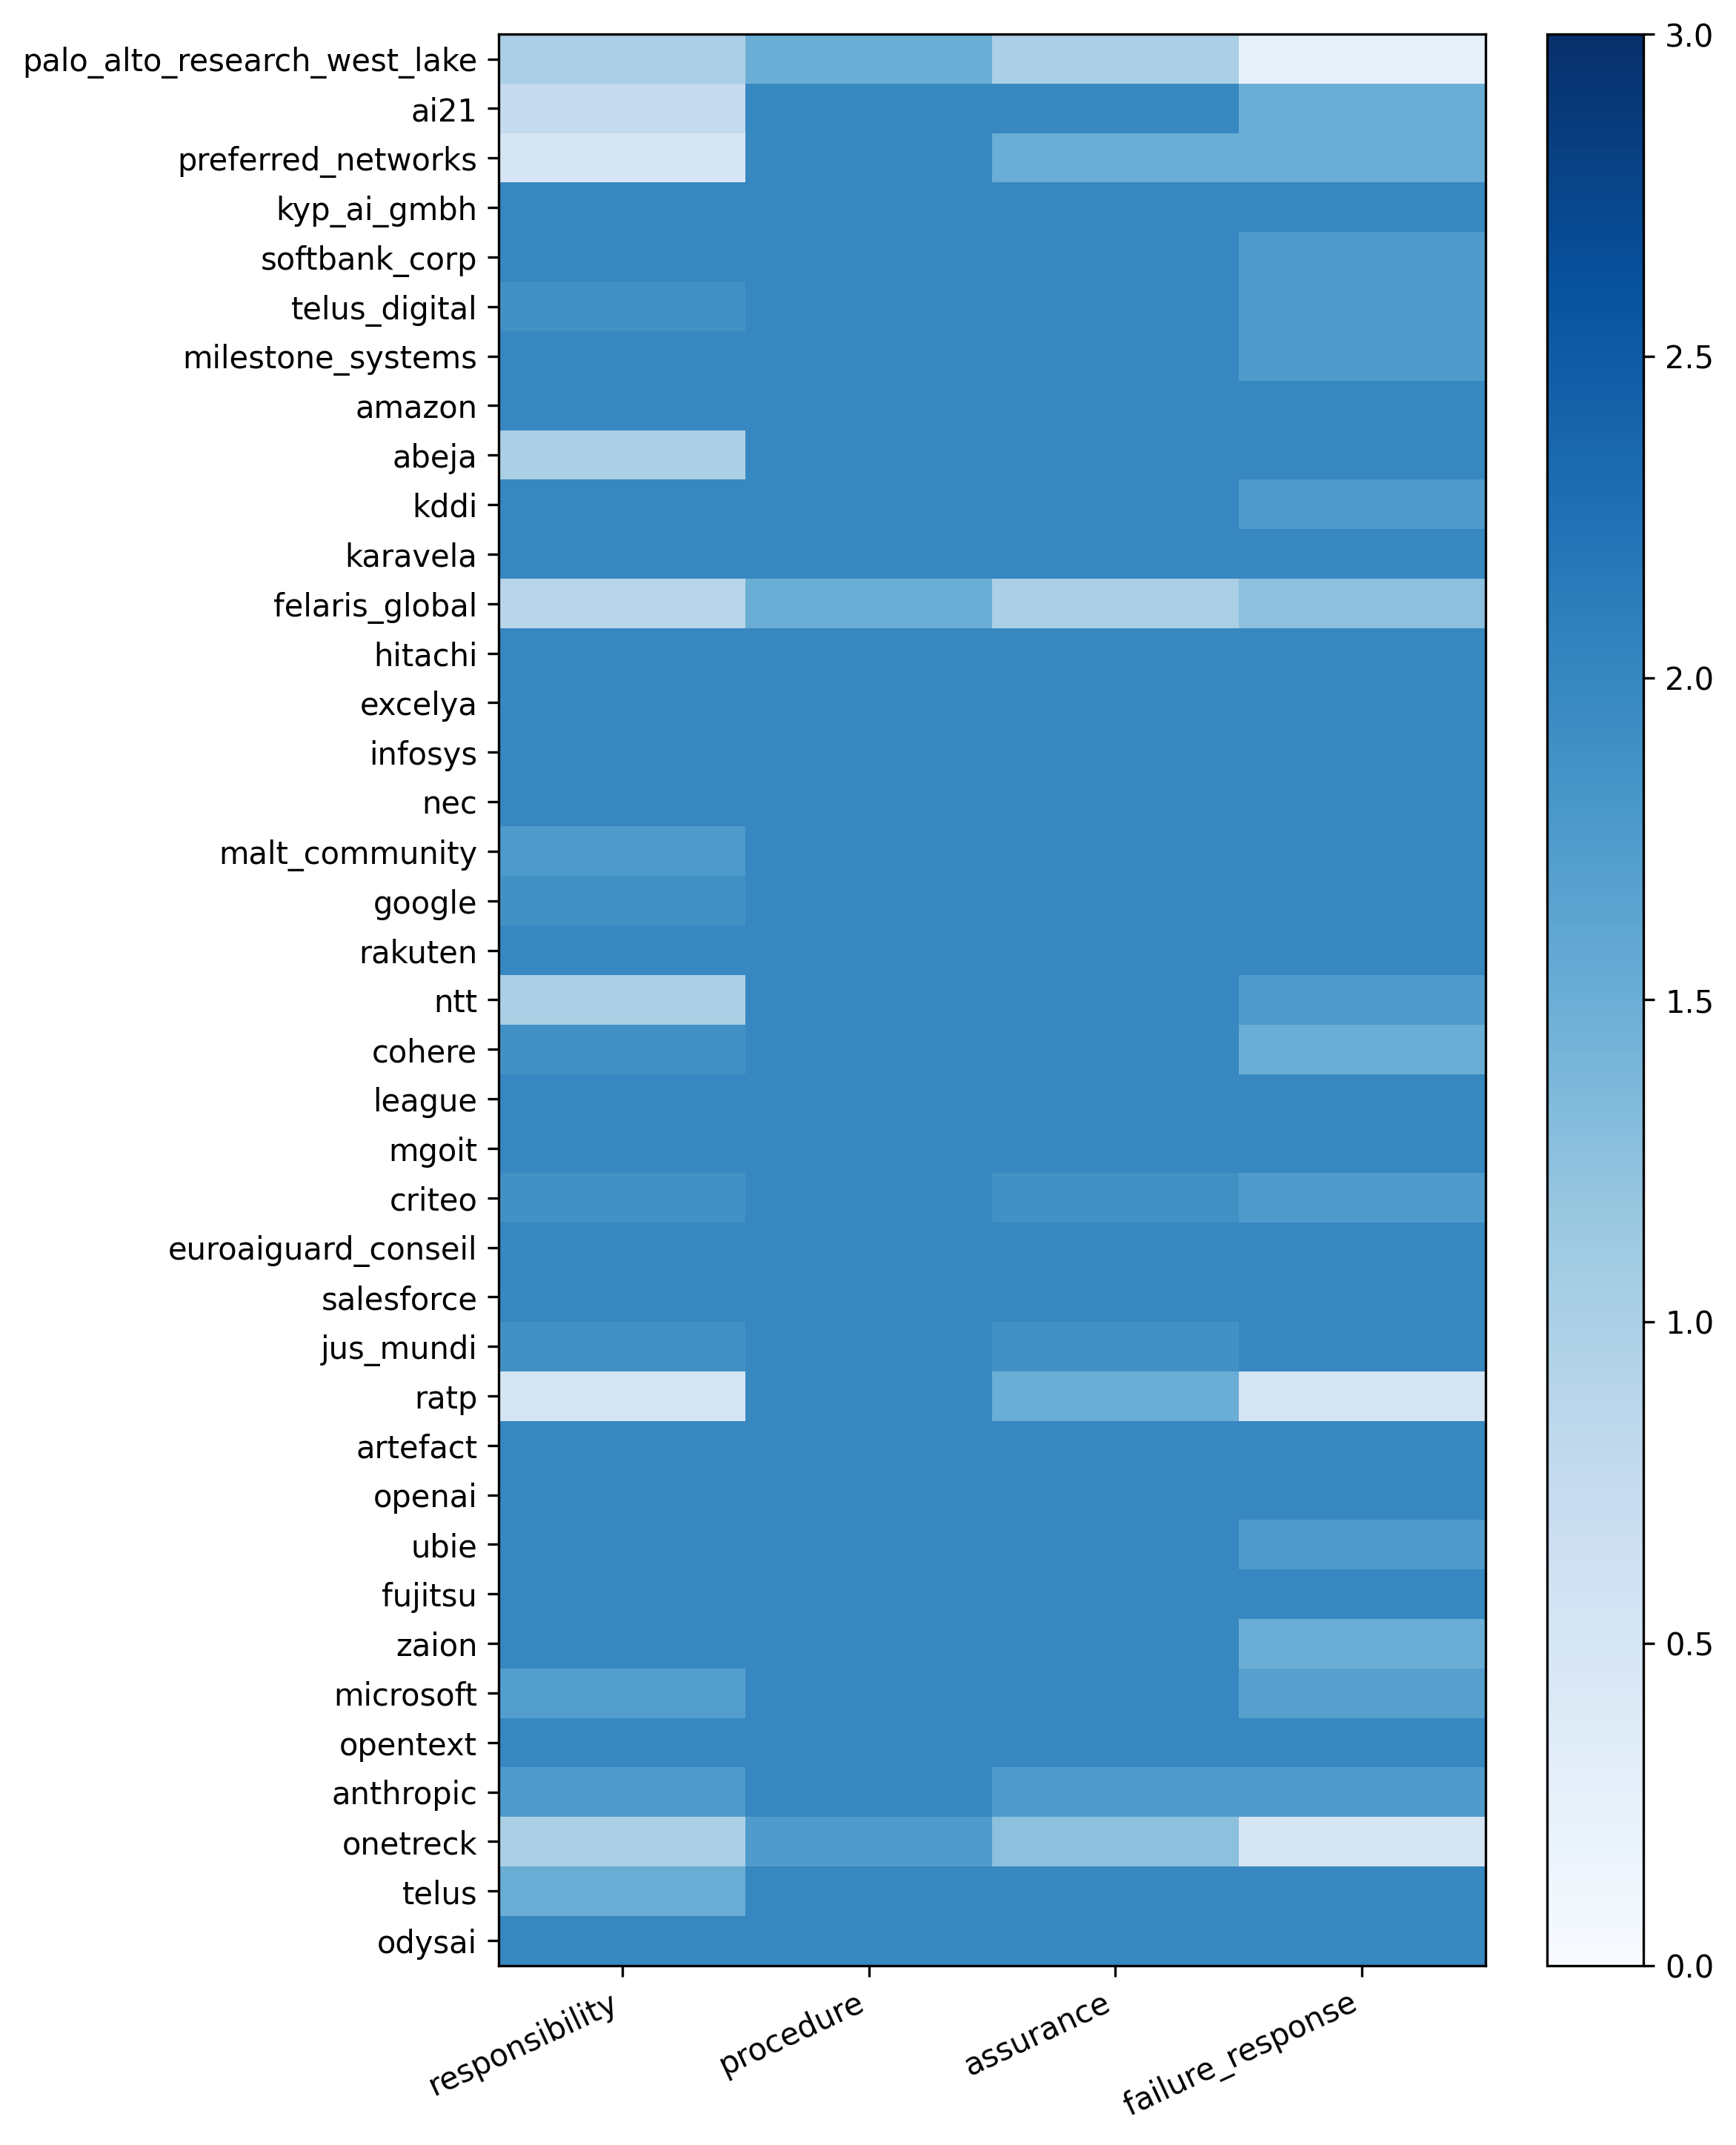

,row,responsibility,procedure,assurance,failure_response
0,palo_alto_research_west_lake,1.00,1.5,1.0,0.25
1,ai21,0.75,2.0,2.0,1.50
2,preferred_networks,0.50,2.0,1.5,1.50
3,kyp_ai_gmbh,2.00,2.0,2.0,2.00
4,softbank_corp,2.00,2.0,2.0,1.75


Saved source CSV: RQ1_F1.csv | PDF: RQ1_F1.pdf


### RQ1_F2 — Reviewed specificity versus explicit same-control chains

Annotation provenance: **AI-reviewed; human validation pending**

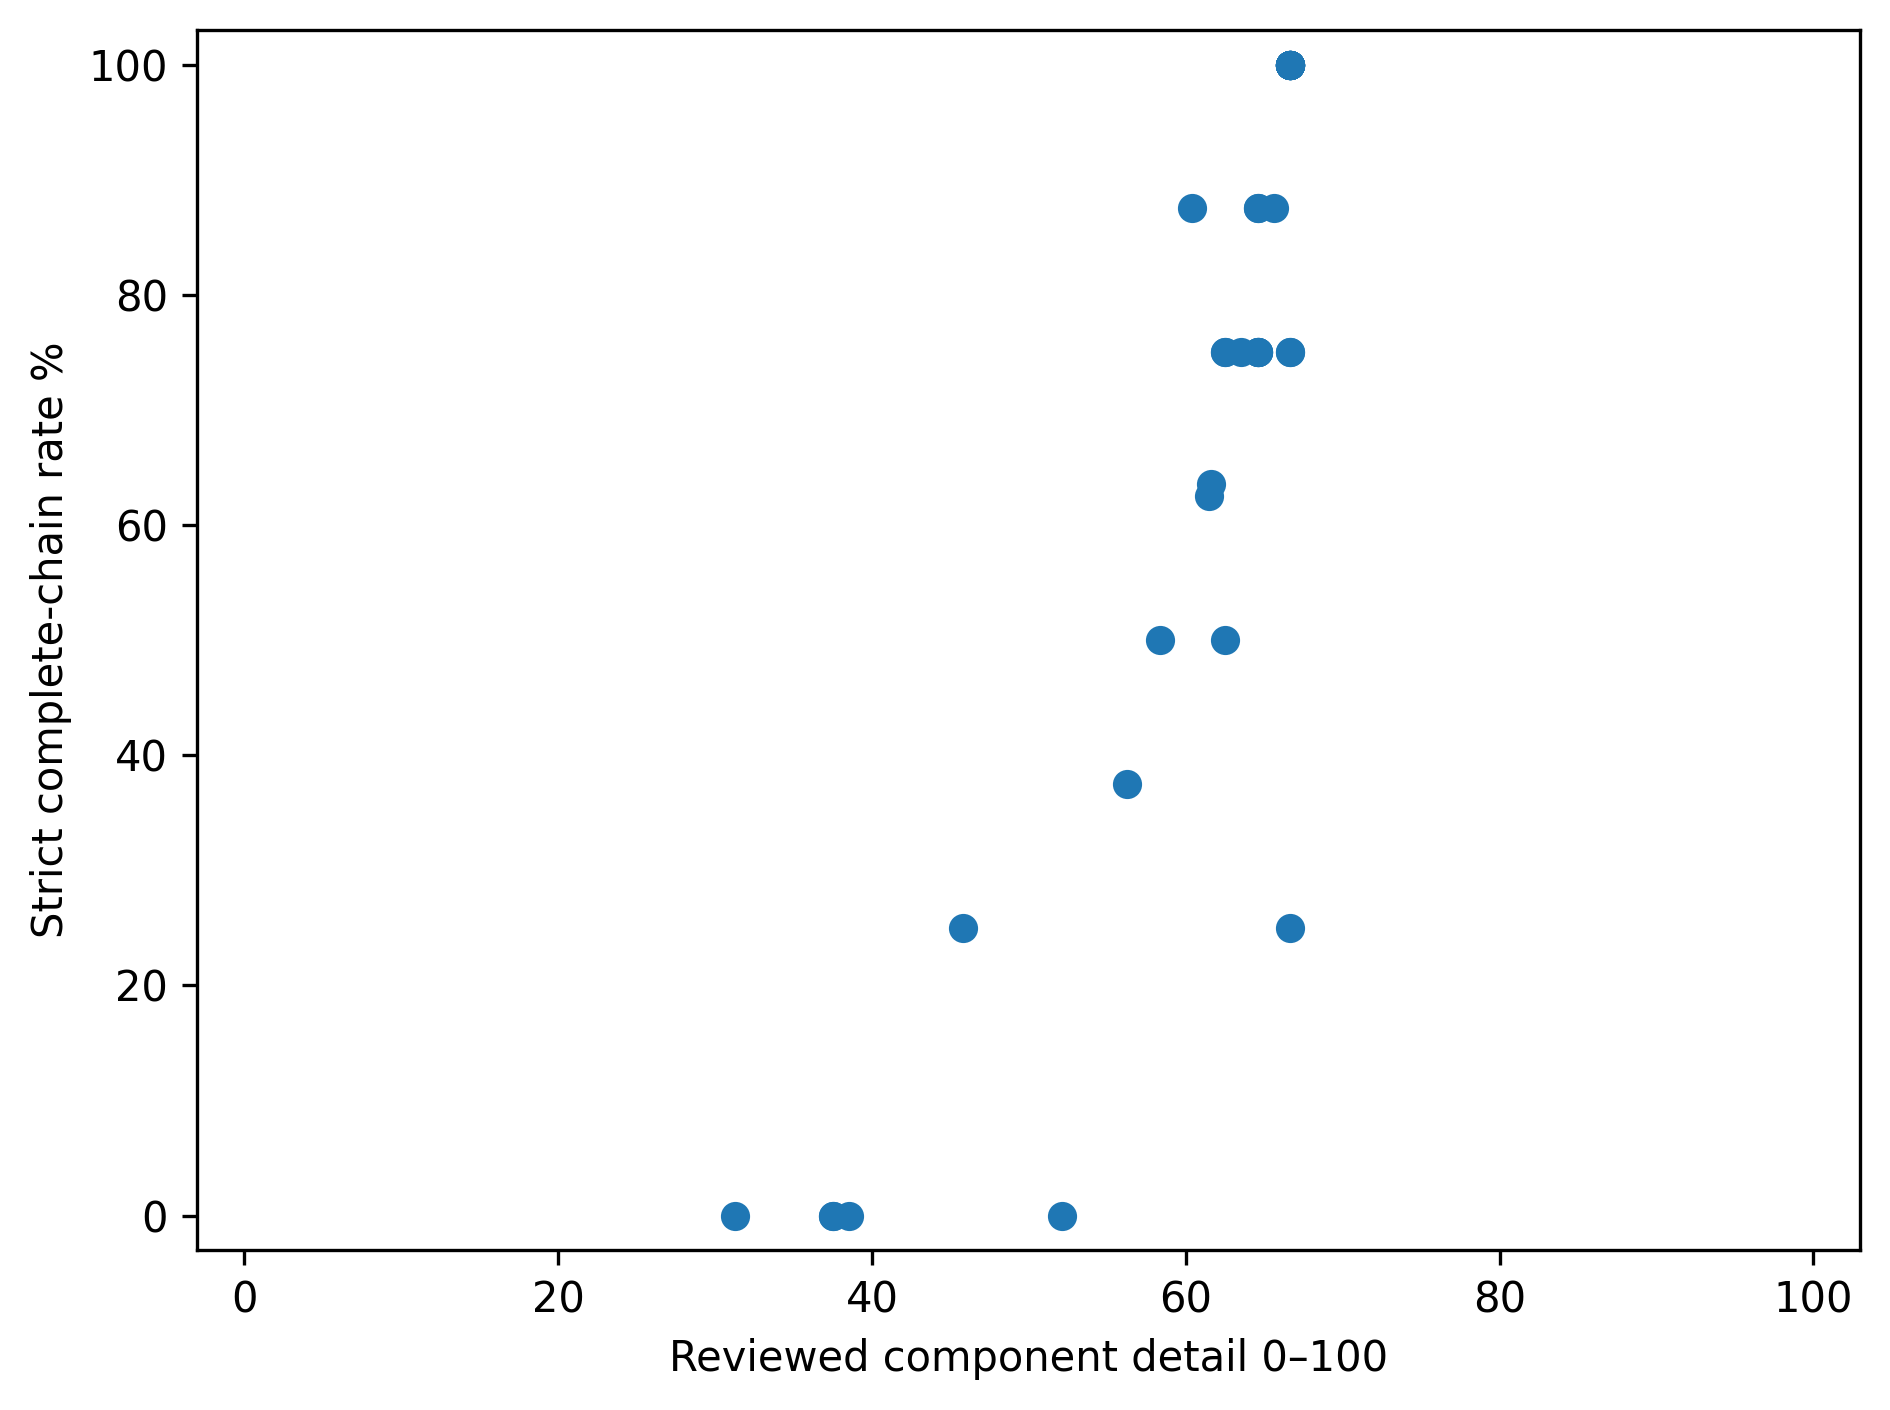

,canonical_id,detail,strict
0,palo_alto_research_west_lake,31.250000,0.0
1,ai21,52.083333,0.0
2,preferred_networks,45.833333,25.0
3,kyp_ai_gmbh,66.666667,75.0
4,softbank_corp,64.583333,75.0


Saved source CSV: RQ1_F2.csv | PDF: RQ1_F2.pdf


### RQ1_T1 — Reviewed specificity prevalence among coded primary controls

Annotation provenance: **AI-reviewed; human validation pending**

,component,code,n_units,denominator
0,responsibility,0,18,188
1,responsibility,1,22,188
2,responsibility,2,148,188
3,responsibility,3,0,188
4,procedure,0,1,188
5,procedure,1,3,188
6,procedure,2,184,188
7,procedure,3,0,188
8,assurance,0,6,188
9,assurance,1,7,188


Saved source CSV: RQ1_T1.csv | PDF: RQ1_T1.pdf


### RQ1_T2 — Specificity threshold sensitivity with all explicit links required

Annotation provenance: **AI-reviewed; human validation pending**

,canonical_id,strict,lenient,detail
0,palo_alto_research_west_lake,0.000000,0.000000,31.250000
1,ai21,0.000000,75.000000,52.083333
2,preferred_networks,25.000000,25.000000,45.833333
3,kyp_ai_gmbh,75.000000,75.000000,66.666667
4,softbank_corp,75.000000,75.000000,64.583333
5,telus_digital,75.000000,75.000000,63.541667
6,milestone_systems,75.000000,75.000000,64.583333
7,amazon,100.000000,100.000000,66.666667
8,abeja,50.000000,50.000000,58.333333
9,kddi,75.000000,75.000000,64.583333


Saved source CSV: RQ1_T2.csv | PDF: RQ1_T2.pdf


In [14]:
# M6 / RQ1 | Display the two figures and two tables, preserving all source/export files.
rq_objects = [item for item in objects if item["id"].startswith("RQ1_")]
assert len(rq_objects) == 4
for item in rq_objects:
    display(Markdown(f"### {item['id']} — {item['caption']}"))
    display(Markdown(f"Annotation provenance: **{ANNOTATION_MODE}**"))
    csv_path = RESULTS_DIR / (item["id"] + ".csv")
    frame = pd.read_csv(csv_path)
    if item["kind"] == "figure":
        display(Image(filename=str(RESULTS_DIR / (item["id"] + ".png")), width=1000))
        display(frame.head())
    else:
        with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", 100):
            display(frame)
    print("Saved source CSV:", csv_path.name, "| PDF:", item["id"] + ".pdf")

## RQ2 — Display all four registered outputs

Each figure is embedded below and its underlying source CSV is retained. Tables display every
row, with the full CSV retained for export. Captions inherit the original implementation's wording.
The actual annotation mode is printed beside the outputs.

### RQ2_F1 — Reviewed lifecycle specificity among applicable company stages

Annotation provenance: **AI-reviewed; human validation pending**

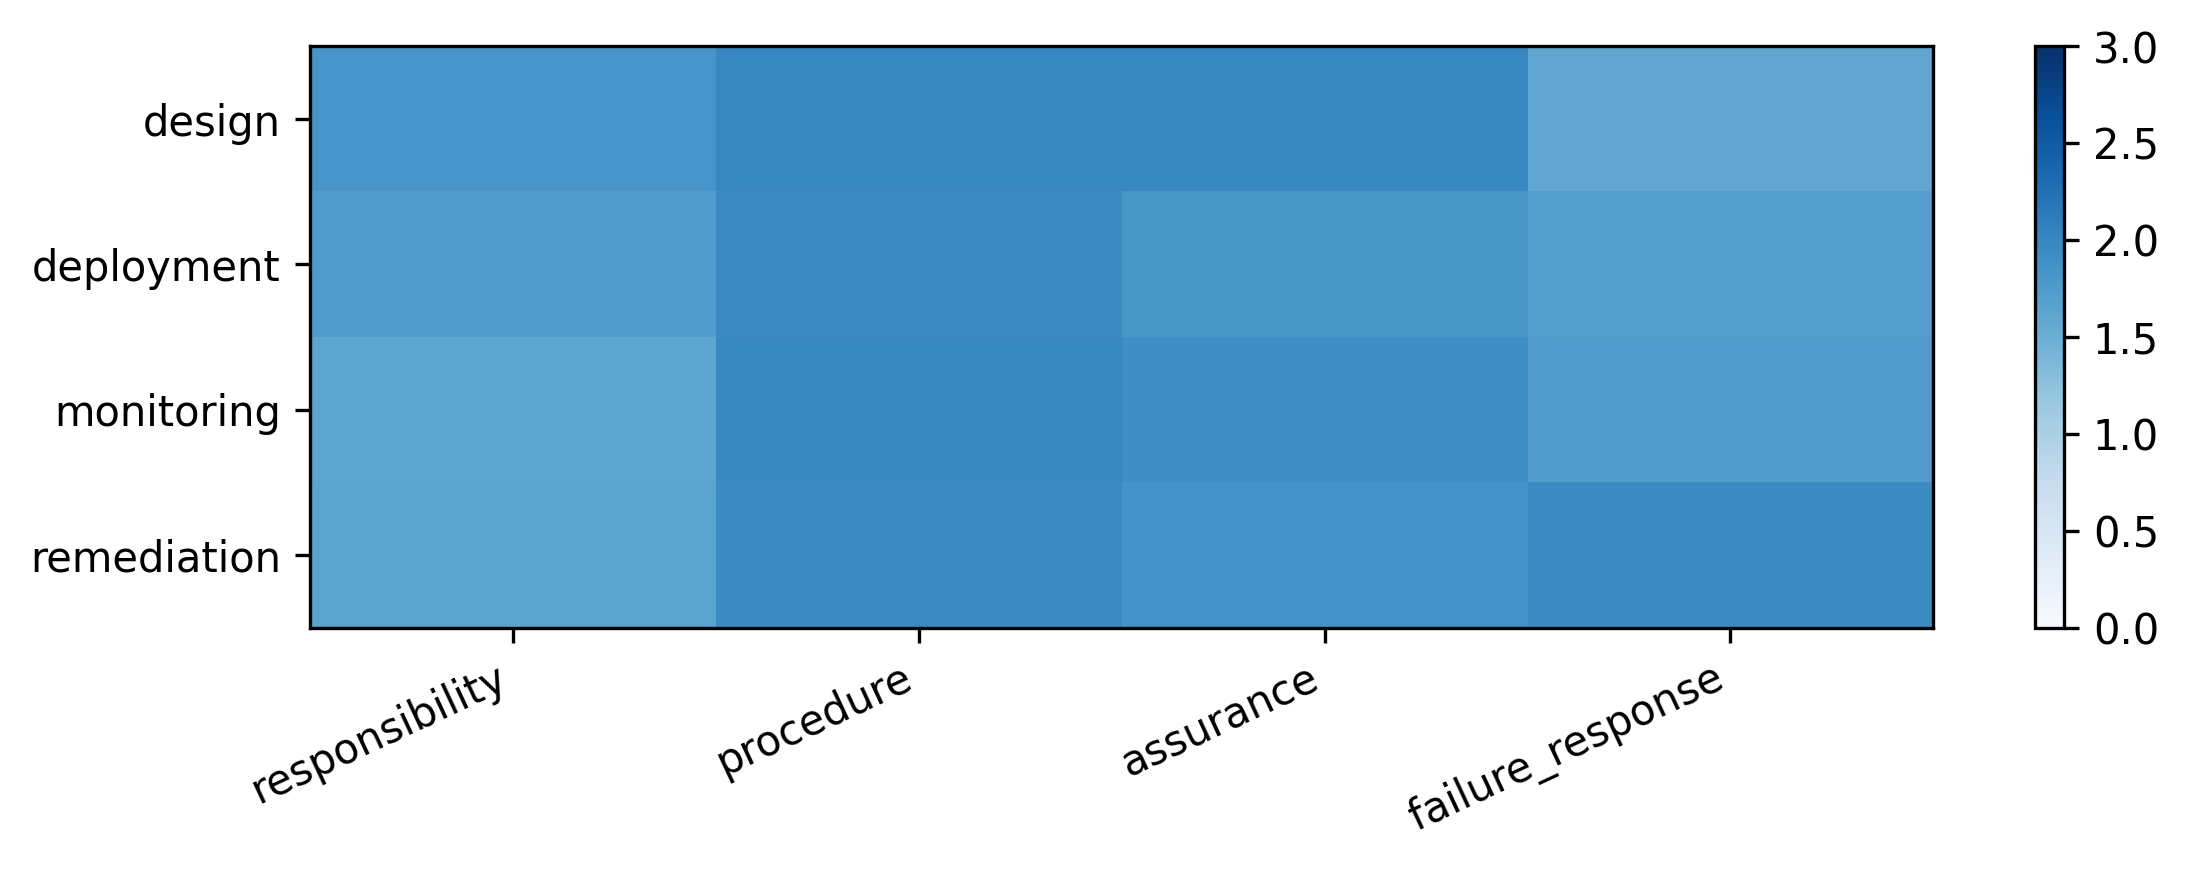

,row,responsibility,procedure,assurance,failure_response
0,design,1.818421,2.000000,2.000000,1.594737
1,deployment,1.729323,1.947368,1.815789,1.699248
2,monitoring,1.624060,1.973684,1.907895,1.725564
3,remediation,1.648718,1.948718,1.833333,1.948718


Saved source CSV: RQ2_F1.csv | PDF: RQ2_F1.pdf


### RQ2_F2 — Equal-report lifecycle rates with applicable-stage denominators

Annotation provenance: **AI-reviewed; human validation pending**

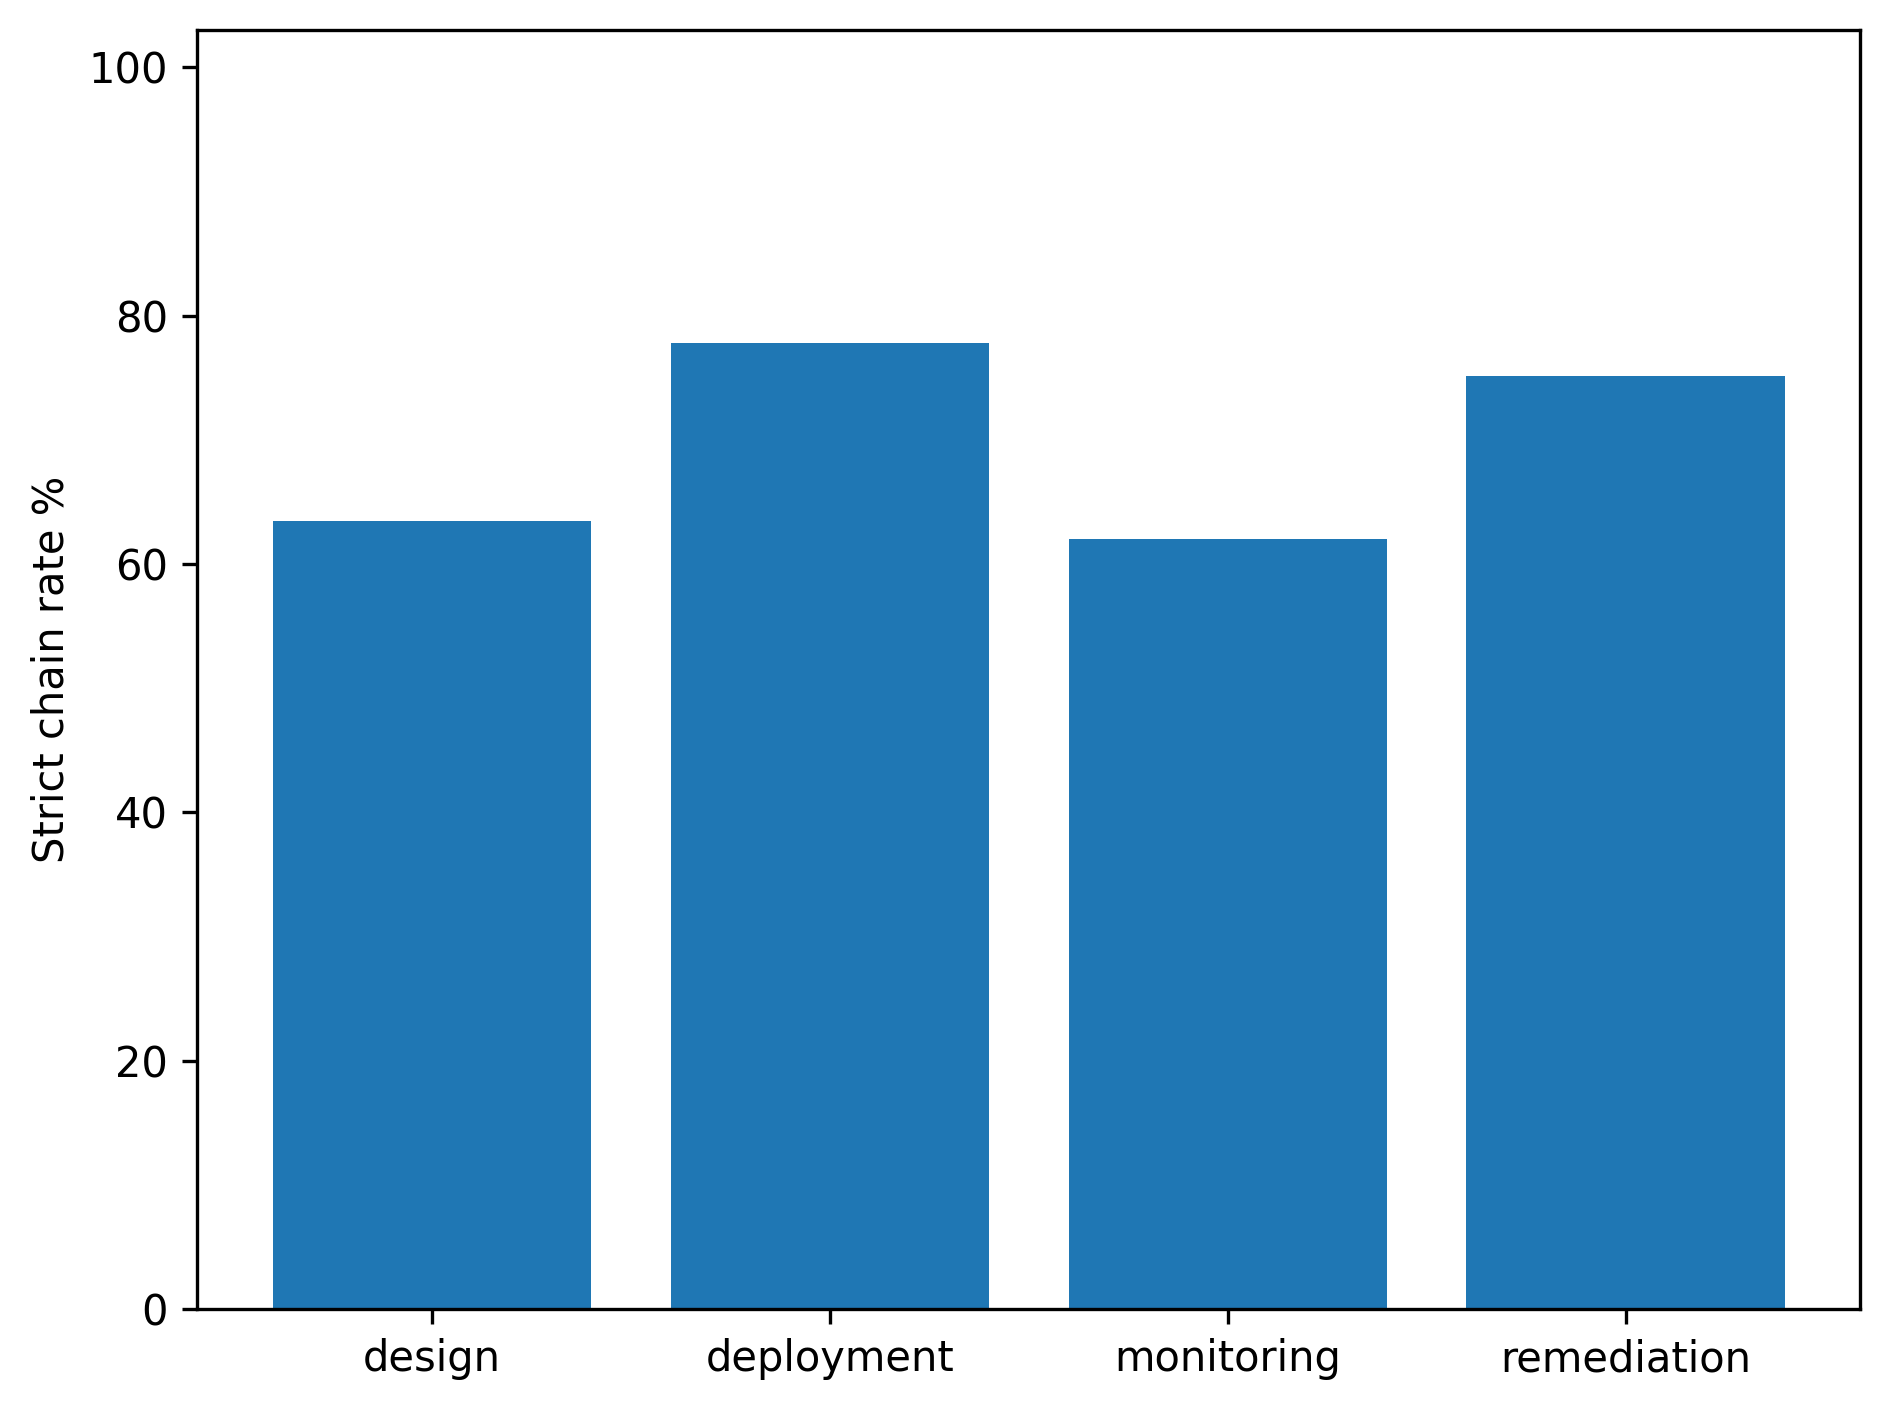

,stage,rate,n_reports
0,design,63.421053,38
1,deployment,77.819549,38
2,monitoring,62.030075,38
3,remediation,75.128205,39


Saved source CSV: RQ2_F2.csv | PDF: RQ2_F2.pdf


### RQ2_T1 — Missing specific components and explicit links

Annotation provenance: **AI-reviewed; human validation pending**

,stage,missing,n_units
0,deployment,assurance_failure_response,1
1,deployment,complete,34
2,deployment,"failure_response,assurance_failure_response",3
3,deployment,responsibility,1
4,deployment,"responsibility,assurance,failure_response,responsibility_procedure,procedure_assurance,assurance...",3
5,deployment,"responsibility,failure_response,responsibility_procedure,assurance_failure_response",2
6,deployment,"responsibility,procedure,assurance,failure_response,responsibility_procedure,procedure_assurance...",1
7,deployment,"responsibility,responsibility_procedure",1
8,design,assurance_failure_response,2
9,design,complete,29


Saved source CSV: RQ2_T1.csv | PDF: RQ2_T1.pdf


### RQ2_T2 — Same-control continuity only among explicitly matched reviewed controls

Annotation provenance: **AI-reviewed; human validation pending**

,transition,matched_controls,complete_both,percent
0,design to deployment,28,22,78.571429
1,deployment to monitoring,12,8,66.666667
2,monitoring to remediation,26,22,84.615385


Saved source CSV: RQ2_T2.csv | PDF: RQ2_T2.pdf


In [15]:
# M6 / RQ2 | Display the two figures and two tables, preserving all source/export files.
rq_objects = [item for item in objects if item["id"].startswith("RQ2_")]
assert len(rq_objects) == 4
for item in rq_objects:
    display(Markdown(f"### {item['id']} — {item['caption']}"))
    display(Markdown(f"Annotation provenance: **{ANNOTATION_MODE}**"))
    csv_path = RESULTS_DIR / (item["id"] + ".csv")
    frame = pd.read_csv(csv_path)
    if item["kind"] == "figure":
        display(Image(filename=str(RESULTS_DIR / (item["id"] + ".png")), width=1000))
        display(frame.head())
    else:
        with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", 100):
            display(frame)
    print("Saved source CSV:", csv_path.name, "| PDF:", item["id"] + ".pdf")

## RQ3 — Display all four registered outputs

Each figure is embedded below and its underlying source CSV is retained. Tables display every
row, with the full CSV retained for export. Captions inherit the original implementation's wording.
The actual annotation mode is printed beside the outputs.

### RQ3_F1 — Descriptive countries using latest reviewed corporate reports

Annotation provenance: **AI-reviewed; human validation pending**

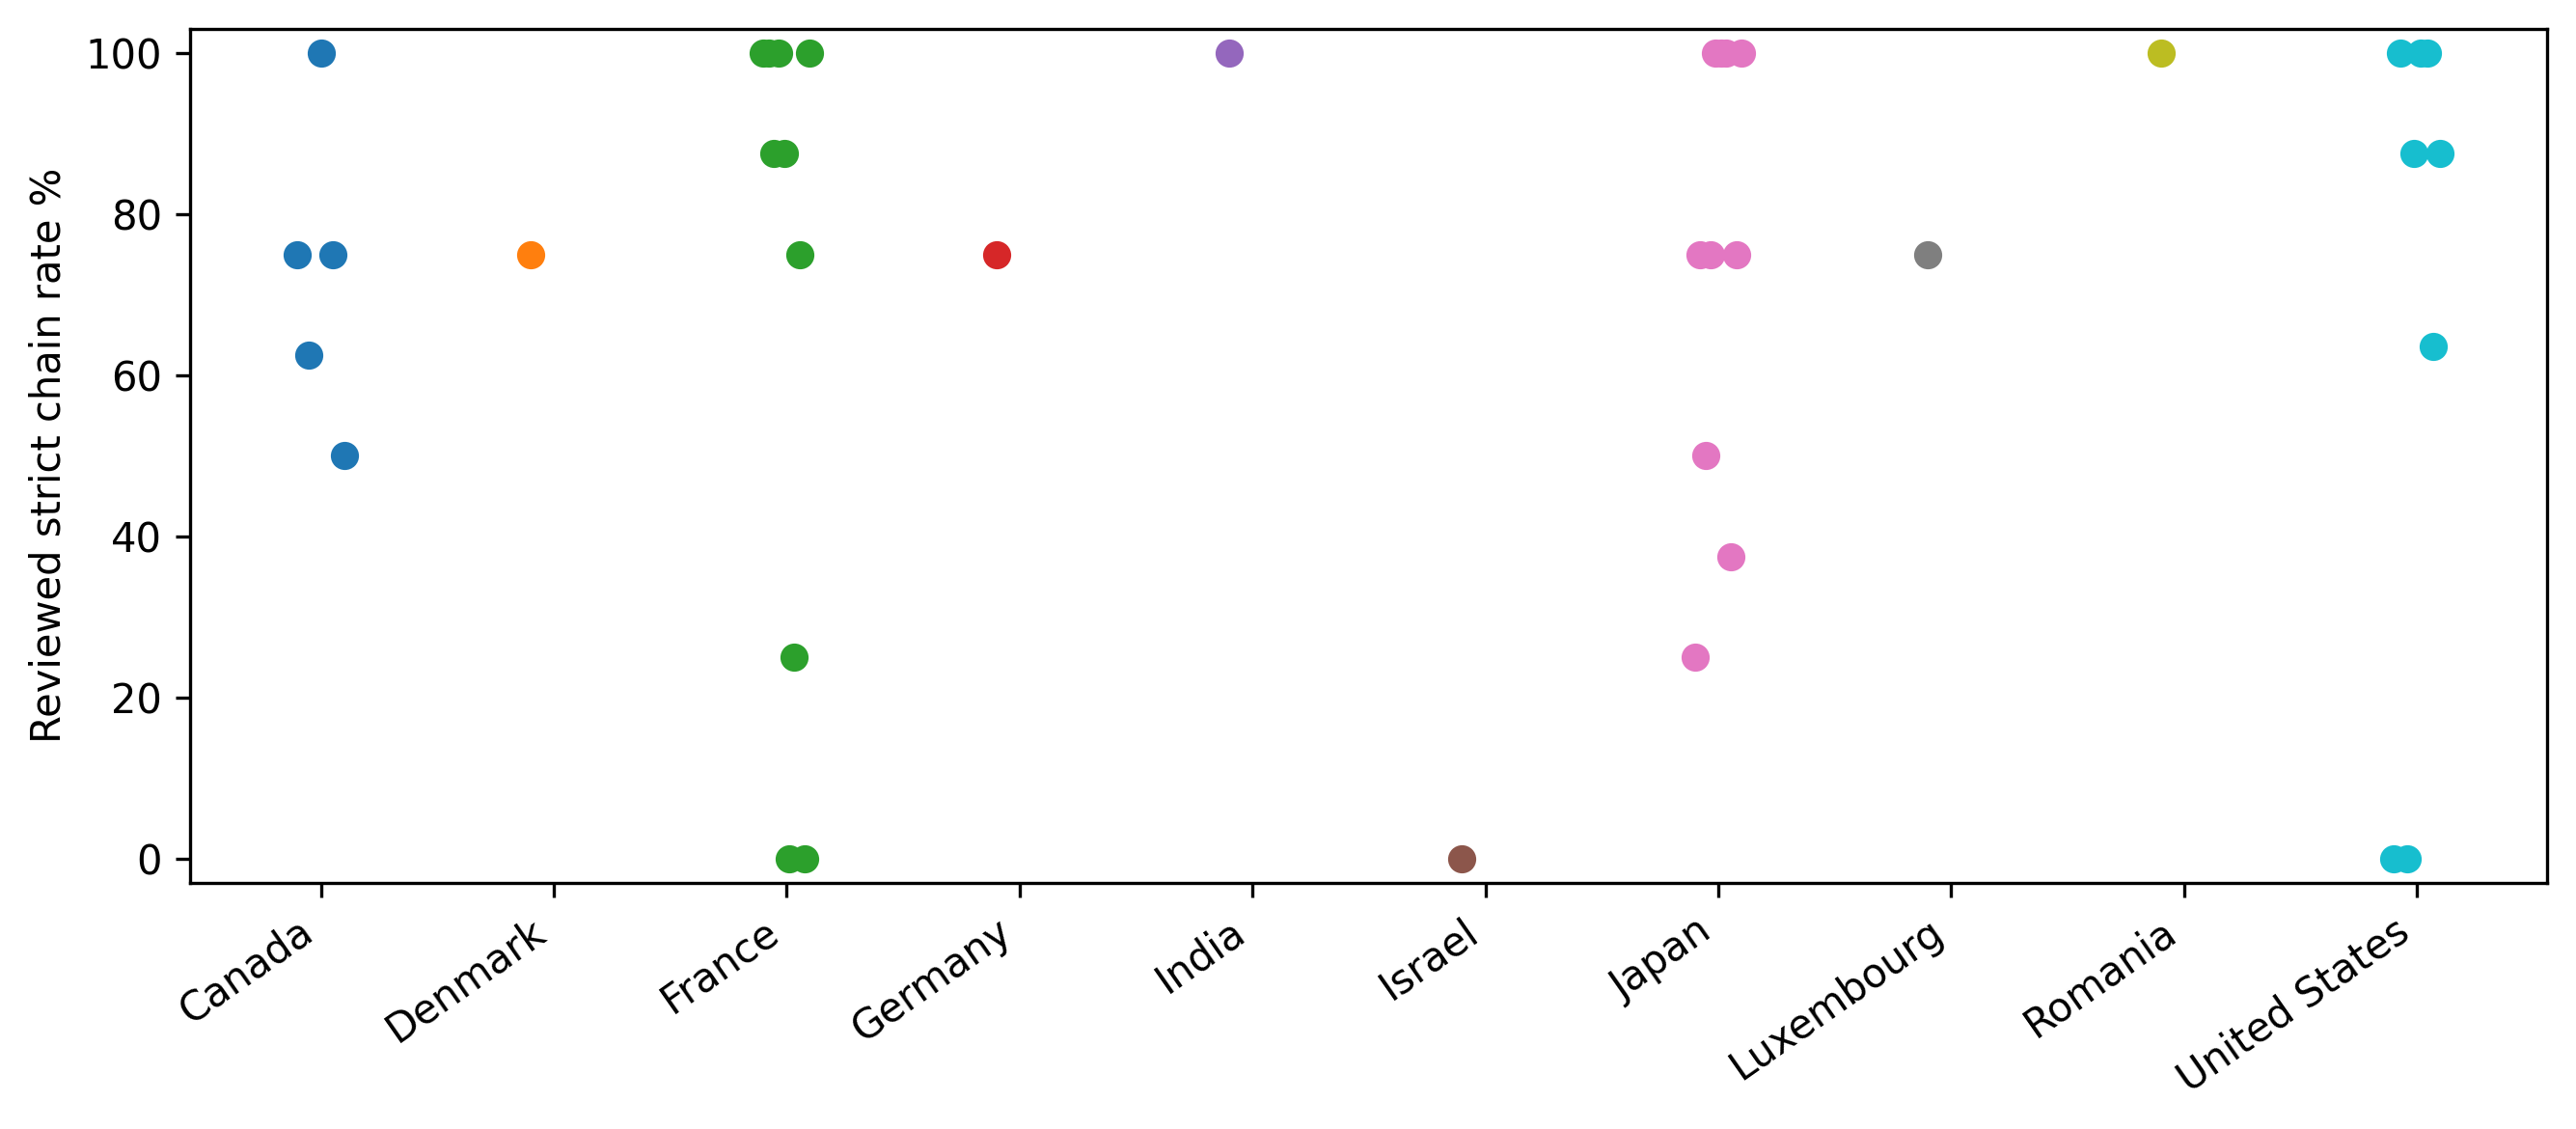

,canonical_id,Country,strict
0,palo_alto_research_west_lake,United States,0.0
1,ai21,Israel,0.0
2,preferred_networks,Japan,25.0
3,kyp_ai_gmbh,Germany,75.0
4,softbank_corp,Japan,75.0


Saved source CSV: RQ3_F1.csv | PDF: RQ3_F1.pdf


### RQ3_F2 — All reviewed reports by period; repeated firms and questionnaire changes remain confounders

Annotation provenance: **AI-reviewed; human validation pending**

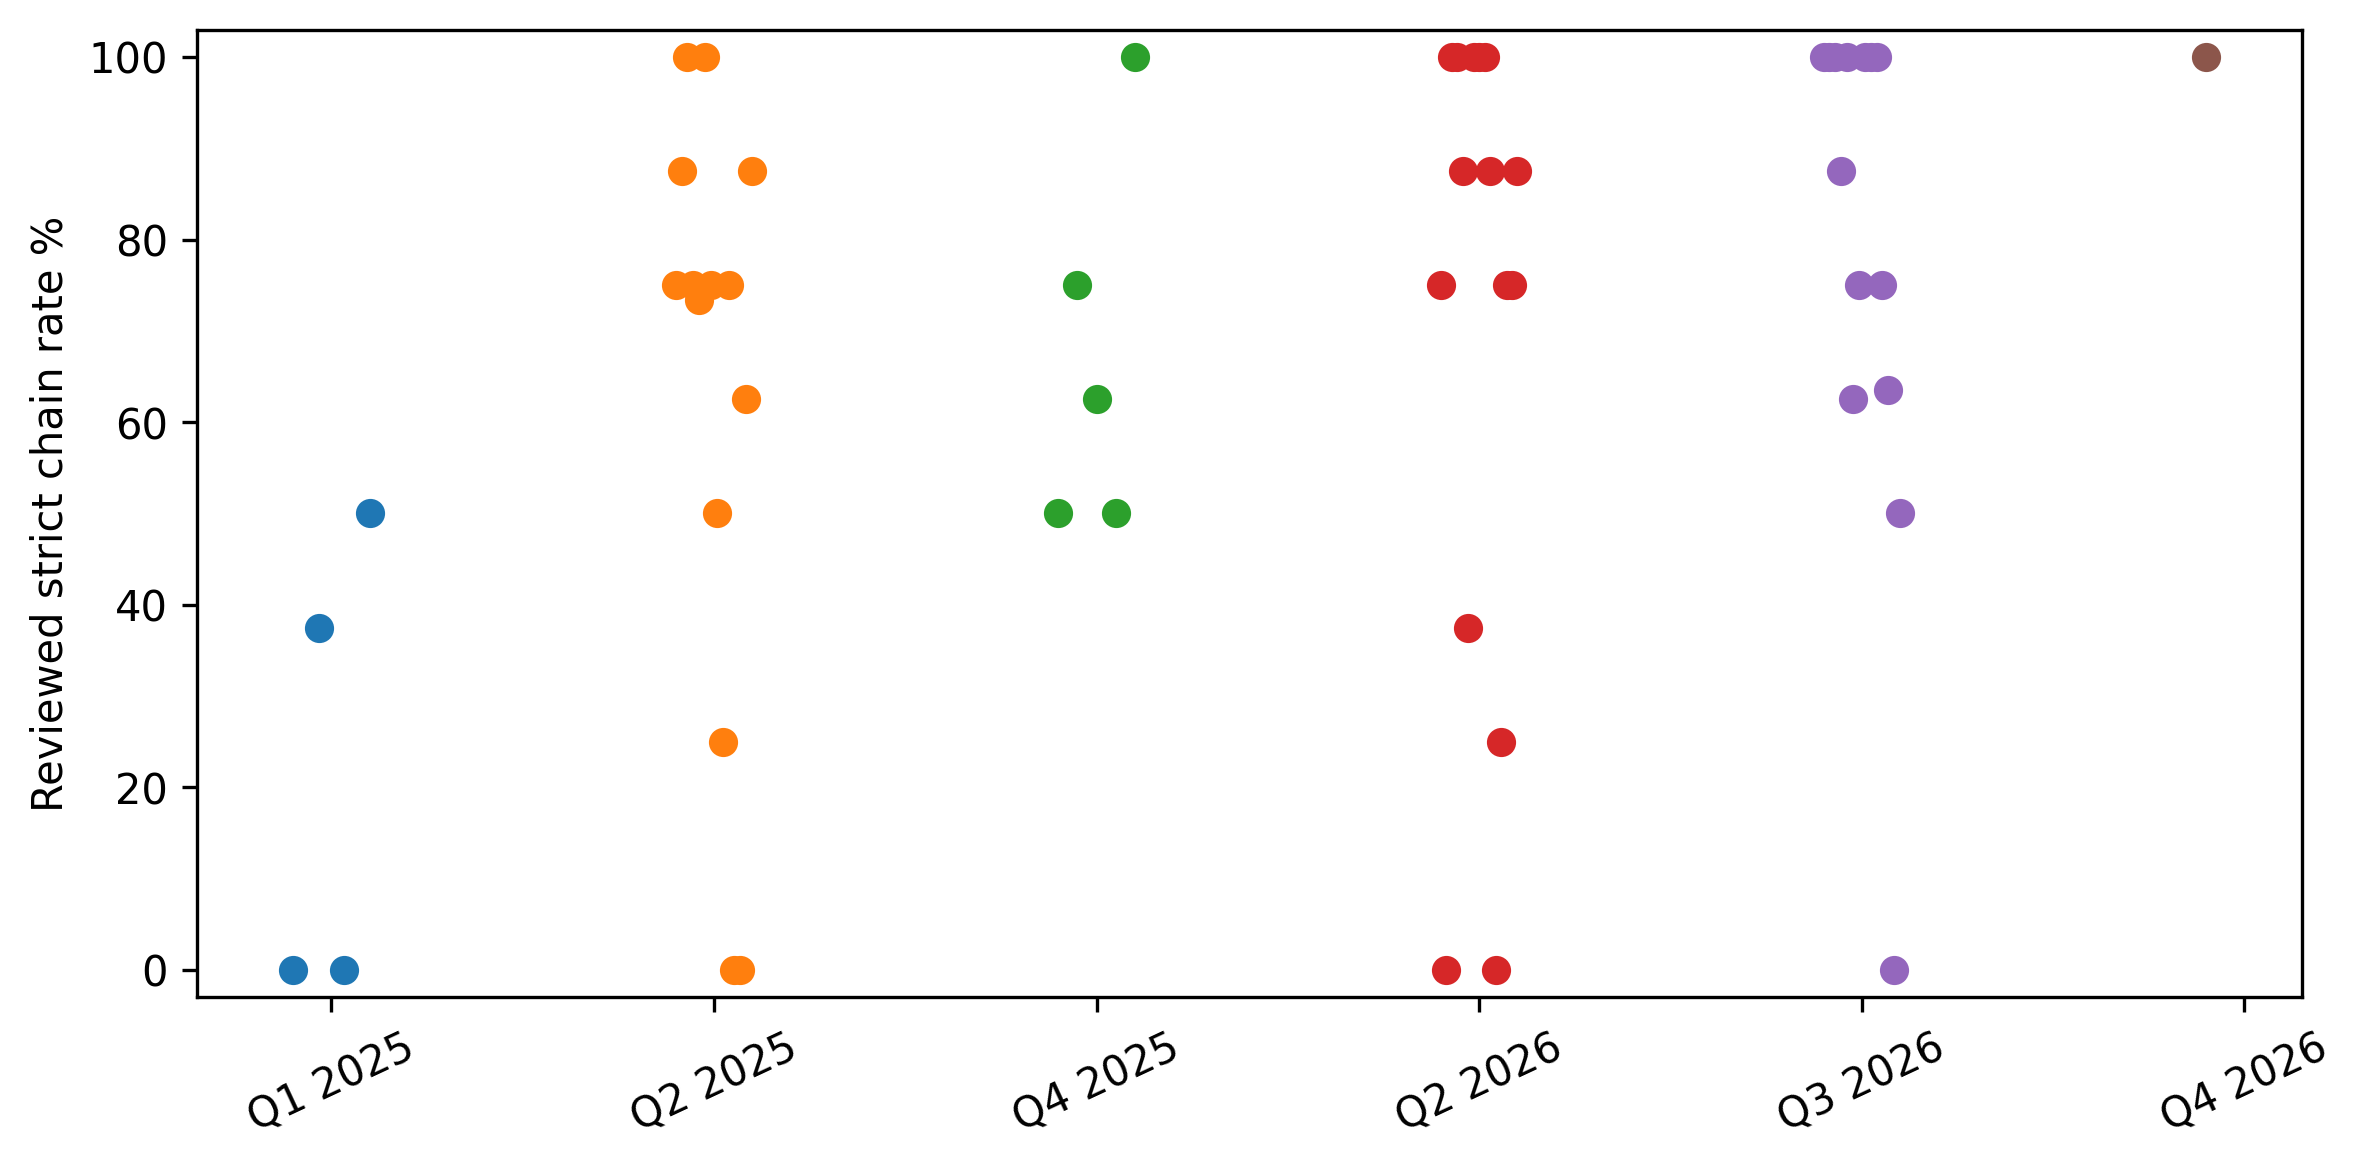

,canonical_id,report_id,Reporting Period,strict
0,kddi,00b26cd7065ffe3d94b5,Q2 2026,75.0
1,kyp_ai_gmbh,063635f8ee77df38c1d3,Q2 2025,75.0
2,openai,07f340a3d8c8829f1d02,Q2 2025,87.5
3,karavela,0fa114622d08a40b42d7,Q3 2026,100.0
4,felaris_global,10649100904a64788def,Q2 2026,0.0


Saved source CSV: RQ3_F2.csv | PDF: RQ3_F2.pdf


### RQ3_T1 — Country period and observed questionnaire composition

Annotation provenance: **AI-reviewed; human validation pending**

,Country,Reporting Period,template_fingerprint,n_reports
0,Canada,Q2 2025,4b21469e88a23928fb57,2
1,Canada,Q2 2026,216ad889e97313356c55,1
2,Canada,Q2 2026,a6926f075206761309b7,1
3,Canada,Q3 2026,5d6f23af2c5c715bc084,1
4,Canada,Q3 2026,78acf6a9d42efc3a50cb,1
5,Denmark,Q4 2025,4b21469e88a23928fb57,1
6,France,Q2 2026,743ace41e9bd8f07b2fd,1
7,France,Q2 2026,7d8acf4761d16273d4dd,1
8,France,Q2 2026,b7bde739cde3aa1f71bc,1
9,France,Q2 2026,d3fee061232e3fc69575,1


Saved source CSV: RQ3_T1.csv | PDF: RQ3_T1.pdf


### RQ3_T2 — Exploratory linear country contrasts adjusted for response length and questionnaire fingerprint; noncausal

Annotation provenance: **AI-reviewed; human validation pending**

,term,reason
0,not estimable,Insufficient residual degrees of freedom or confounded country/template design


Saved source CSV: RQ3_T2.csv | PDF: RQ3_T2.pdf


In [16]:
# M6 / RQ3 | Display the two figures and two tables, preserving all source/export files.
rq_objects = [item for item in objects if item["id"].startswith("RQ3_")]
assert len(rq_objects) == 4
for item in rq_objects:
    display(Markdown(f"### {item['id']} — {item['caption']}"))
    display(Markdown(f"Annotation provenance: **{ANNOTATION_MODE}**"))
    csv_path = RESULTS_DIR / (item["id"] + ".csv")
    frame = pd.read_csv(csv_path)
    if item["kind"] == "figure":
        display(Image(filename=str(RESULTS_DIR / (item["id"] + ".png")), width=1000))
        display(frame.head())
    else:
        with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", 100):
            display(frame)
    print("Saved source CSV:", csv_path.name, "| PDF:", item["id"] + ".pdf")

## RQ4 — Display all four registered outputs

Each figure is embedded below and its underlying source CSV is retained. Tables display every
row, with the full CSV retained for export. Captions inherit the original implementation's wording.
The actual annotation mode is printed beside the outputs.

### RQ4_F1 — Automated rules versus adjudicated substantive evidence and complete chains

Annotation provenance: **AI-reviewed; human validation pending**

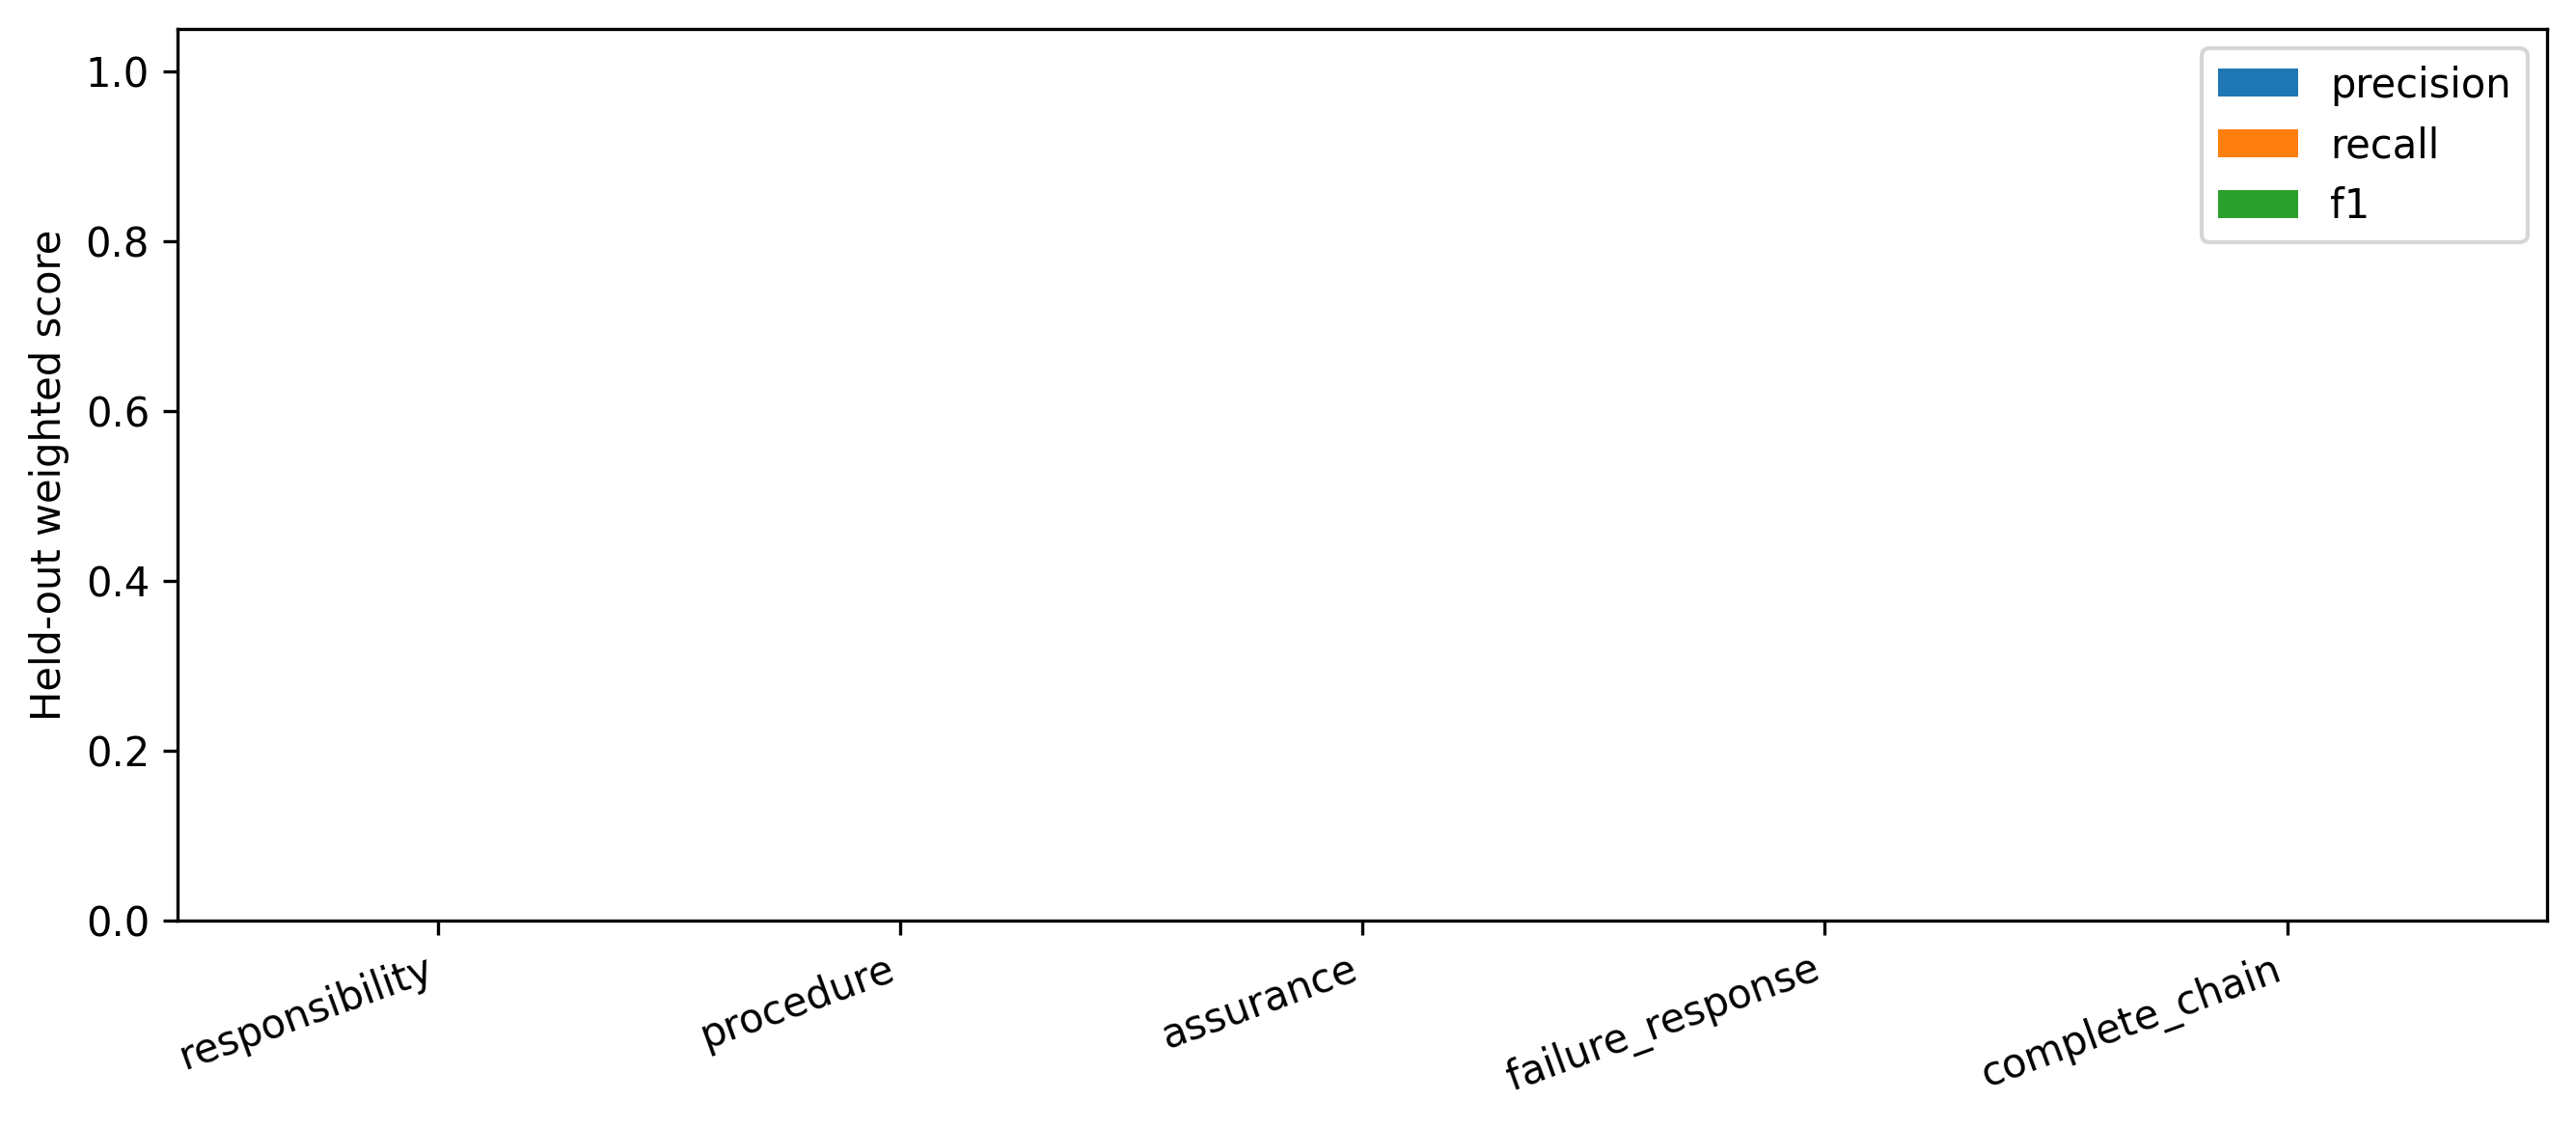

,dimension,held_out_n,gold_positive_n,weighted_precision,weighted_recall,weighted_f1,precision_low,precision_high,recall_low,recall_high,f1_low,f1_high
0,responsibility,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,procedure,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,assurance,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,failure_response,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,complete_chain,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


Saved source CSV: RQ4_F1.csv | PDF: RQ4_F1.pdf


### RQ4_F2 — Independent held-out coding agreement; ordinal scores use quadratic weights

Annotation provenance: **AI-reviewed; human validation pending**

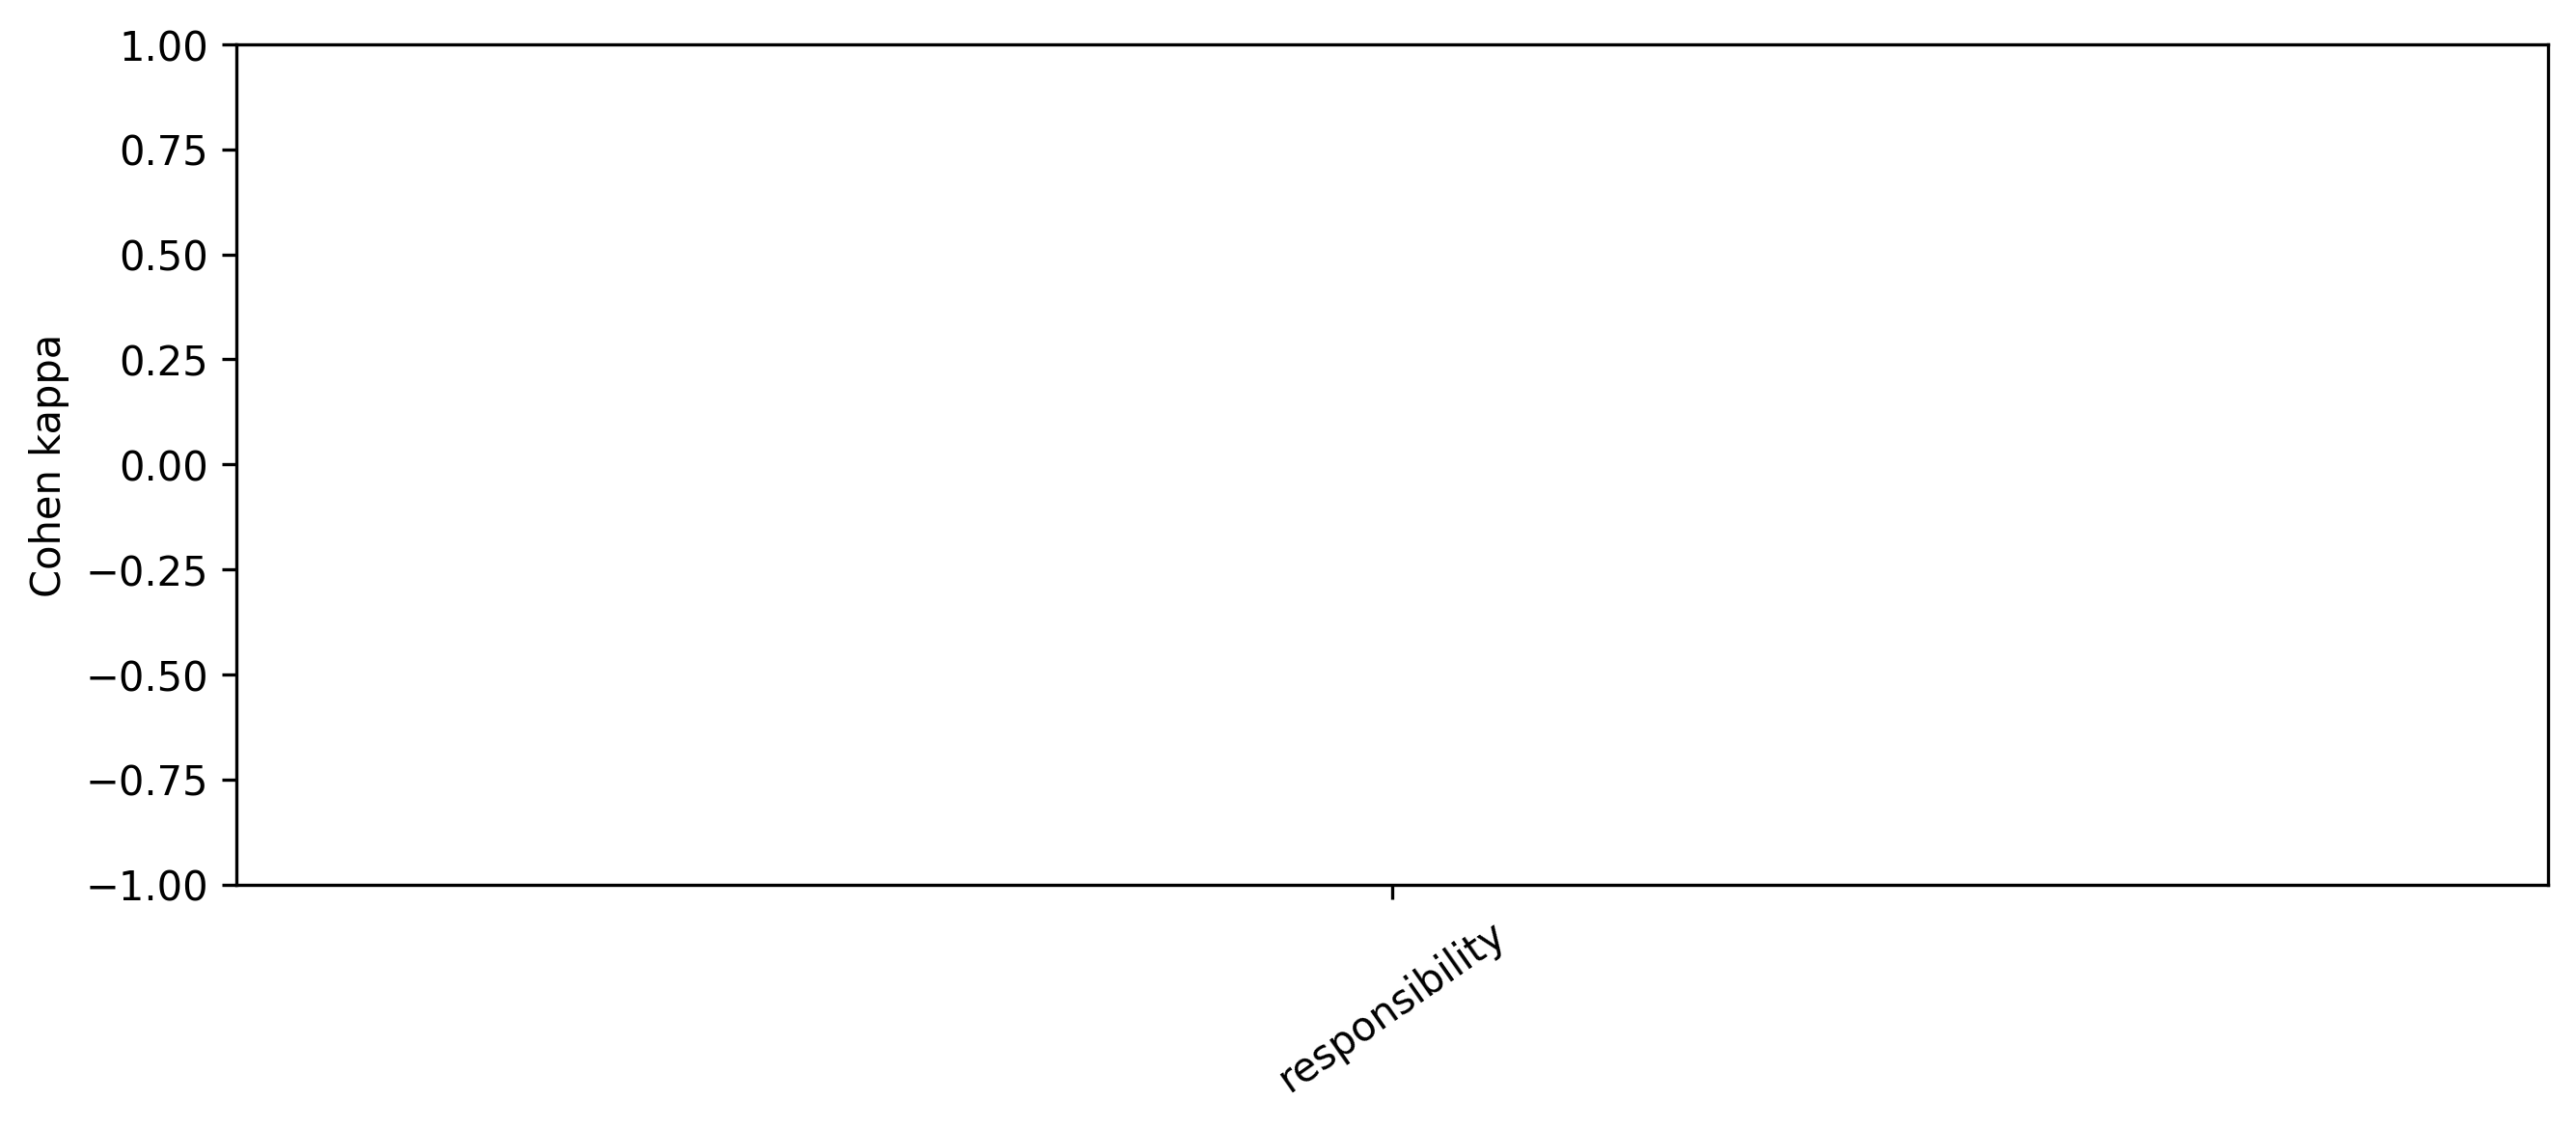

,dimension,n,raw_agreement,kappa
0,responsibility,112,1.0,NaN
1,procedure,112,1.0,NaN
2,assurance,112,1.0,NaN
3,failure_response,112,1.0,NaN
4,responsibility_procedure,112,1.0,NaN


Saved source CSV: RQ4_F2.csv | PDF: RQ4_F2.pdf


### RQ4_T1 — Weighted held-out precision recall F1 and company-bootstrap uncertainty

Annotation provenance: **AI-reviewed; human validation pending**

,dimension,held_out_n,gold_positive_n,weighted_precision,weighted_recall,weighted_f1,precision_low,precision_high,recall_low,recall_high,f1_low,f1_high
0,responsibility,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,procedure,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,assurance,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,failure_response,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,complete_chain,112,0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


Saved source CSV: RQ4_T1.csv | PDF: RQ4_T1.pdf


### RQ4_T2 — Independent coding agreement with denominators; undefined kappa retained as missing

Annotation provenance: **AI-reviewed; human validation pending**

,dimension,n,raw_agreement,kappa
0,responsibility,112,1.0,NaN
1,procedure,112,1.0,NaN
2,assurance,112,1.0,NaN
3,failure_response,112,1.0,NaN
4,responsibility_procedure,112,1.0,NaN
5,procedure_assurance,112,1.0,NaN
6,assurance_failure_response,112,1.0,NaN


Saved source CSV: RQ4_T2.csv | PDF: RQ4_T2.pdf


In [17]:
# M6 / RQ4 | Display the two figures and two tables, preserving all source/export files.
rq_objects = [item for item in objects if item["id"].startswith("RQ4_")]
assert len(rq_objects) == 4
for item in rq_objects:
    display(Markdown(f"### {item['id']} — {item['caption']}"))
    display(Markdown(f"Annotation provenance: **{ANNOTATION_MODE}**"))
    csv_path = RESULTS_DIR / (item["id"] + ".csv")
    frame = pd.read_csv(csv_path)
    if item["kind"] == "figure":
        display(Image(filename=str(RESULTS_DIR / (item["id"] + ".png")), width=1000))
        display(frame.head())
    else:
        with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", 100):
            display(frame)
    print("Saved source CSV:", csv_path.name, "| PDF:", item["id"] + ".pdf")

## M6 — Interpret the actual run and retain statistical limitations

This cell derives a short interpretation from the newly generated files. Selected-control rates
use the study's units and weighting. Country comparisons are descriptive. A model that lacks
rank or residual degrees of freedom remains reported as non-estimable.

In [18]:
# M6 / RQ1–RQ4 | Interpret calculated values and the actual model diagnostics without filling missing estimates.
report_scores = pd.read_csv(RESULTS_DIR / "reviewed_report_scores.csv")
latest_scores = report_scores.sort_values(["date", "report_id"]).groupby("canonical_id", sort=False).tail(1)
diagnostics = json.loads((RESULTS_DIR / "context_model_diagnostics.json").read_text())
mean_chain_rate = latest_scores["strict"].mean()
display(Markdown(
    f"The current run covers **{len(eligible_reports)} reports** from **{len(latest_scores)} canonical reporting entities**. "
    f"The mean latest-report strict-chain rate across selected, stage-balanced control units is **{mean_chain_rate:.2f}%**. "
    f"This denominator concerns the selected coded units. Annotation provenance is **{ANNOTATION_MODE}**."
))
display(pd.DataFrame(diagnostics.items(), columns=["diagnostic", "value"]))
if diagnostics["status"] == "not_estimable":
    display(Markdown(
        "**RQ3 limitation.** Adjusted country contrasts are non-estimable with this design. "
        "The displayed RQ3_T2 records that outcome. Descriptive comparisons remain available, "
        "with no causal interpretation or substituted coefficients."
    ))
display(Markdown("""
**Interpretation boundaries**

- Public disclosures concern what was reported, with self-selection and reporting incentives.
- Country labels, company identities, parent-group dependence and questionnaire equivalence require source review.
- Multiple answers, controls and stages within a company are dependent observations.
- Selected control units do not establish a comprehensive universe of controls.
- Current versus prospective mechanisms and score-3 references need consistent adjudication.
- AI reviewers share model characteristics and may make correlated errors. Their agreement is insufficient to establish human reliability.
- Artifact contents/access and governance operation were not independently verified in the available AI annotations.
- Weighted bootstrap intervals describe this selected validation sample and cannot establish population-wide or causal inference.
"""))

The current run covers **53 reports** from **39 canonical reporting entities**. The mean latest-report strict-chain rate across selected, stage-balanced control units is **70.22%**. This denominator concerns the selected coded units. Annotation provenance is **AI-reviewed; human validation pending**.

,diagnostic,value
0,n_companies,39
1,n_parameters,38
2,matrix_rank,34
3,status,not_estimable
4,interpretation,"descriptive association, not causal; one lates..."


**RQ3 limitation.** Adjusted country contrasts are non-estimable with this design. The displayed RQ3_T2 records that outcome. Descriptive comparisons remain available, with no causal interpretation or substituted coefficients.


**Interpretation boundaries**

- Public disclosures concern what was reported, with self-selection and reporting incentives.
- Country labels, company identities, parent-group dependence and questionnaire equivalence require source review.
- Multiple answers, controls and stages within a company are dependent observations.
- Selected control units do not establish a comprehensive universe of controls.
- Current versus prospective mechanisms and score-3 references need consistent adjudication.
- AI reviewers share model characteristics and may make correlated errors. Their agreement is insufficient to establish human reliability.
- Artifact contents/access and governance operation were not independently verified in the available AI annotations.
- Weighted bootstrap intervals describe this selected validation sample and cannot establish population-wide or causal inference.


## M6 — Save provenance and build the complete results ZIP

The archive includes all generated figure PDFs/PNGs, all table/source CSVs, evaluation records,
annotation snapshots and run metadata. No synthetic test fixtures are used as research observations.
The executed notebook itself is saved separately by Jupyter/VS Code.

In [20]:
%pip install nbformat nbclient


  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
  Using cached nbclient-0.11.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached fastjsonschema-2.22.3-py3-none-any.whl.metadata (2.1 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached nbformat-5.11.1-py3-none-any.whl (79 kB)
Using cached nbclient-0.11.0-py3-none-any.whl (25 kB)
Using cached fastjsonschema-2.22.3-py3-none-any.whl (28 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)

   ----- ---------------------------------- 1/8 [fastjsonschema]
   ---------- --------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [22]:
# M6 | Copy this run's outputs; allow retrying an interrupted export.
shutil.copytree(
    RESULTS_DIR,
    RUN_DIR / "results",
    dirs_exist_ok=True,
)

shutil.copytree(
    EVALUATION_DIR,
    RUN_DIR / "evaluation",
    dirs_exist_ok=True,
)

snapshot = RUN_DIR / "annotation_inputs"
snapshot.mkdir(parents=True, exist_ok=True)

In [24]:
# M6 | Archive this actual run and verify ZIP integrity and all sixteen expected PDF/CSV pairs.
# M6 | Archive outputs; allow retrying an interrupted export.
shutil.copytree(
    RESULTS_DIR, RUN_DIR / "results", dirs_exist_ok=True
)
shutil.copytree(
    EVALUATION_DIR, RUN_DIR / "evaluation", dirs_exist_ok=True
)
snapshot = RUN_DIR / "annotation_inputs"
snapshot.mkdir(parents=True, exist_ok=True)
for name in review_files + ["eligibility.csv", "frozen_sample.csv", "frozen.json", "lexicon_and_stage_rules.json"]:
    shutil.copyfile(WORKSPACE / name, snapshot / name)
for name in ["AI_REVIEW_PROTOCOL.md", "READ_FIRST.md", "AI_REVIEW_LOG.json", "AI_ADJUDICATION_AUDIT.json"]:
    if (WORKSPACE / name).is_file():
        shutil.copyfile(WORKSPACE / name, snapshot / name)
packages = ["pandas", "numpy", "matplotlib", "scipy", "scikit-learn", "statsmodels", "nbformat", "nbclient"]
versions = {name: importlib.metadata.version(name) for name in packages}
run_provenance = {
    "run_id": RUN_ID, "annotation_mode": ANNOTATION_MODE,
    "workspace_name": WORKSPACE.name, "source_profile": raw_profile,
    "preprocessing_profile": preprocessing_profile,
    "implementation_sha256": sha256(PROJECT_DIR / "implementation.py"),
    "exploratory_sha256": sha256(PROJECT_DIR / "exploratory.py"),
    "annotation_inputs": dict(zip(annotation_provenance.file, annotation_provenance.sha256)),
    "python_version": sys.version.split()[0], "package_versions": versions,
    "context_model": diagnostics, "registered_result_objects": len(objects),
}
(RUN_DIR / "run_provenance.json").write_text(json.dumps(run_provenance, indent=2), encoding="utf-8")
(RUN_DIR / "README.txt").write_text(
    "Final Analysis results archive\nAnnotation mode: " + ANNOTATION_MODE +
    "\nSee run_provenance.json and annotation_inputs for evidence provenance.\n",
    encoding="utf-8"
)
for item in objects:
    for extension in ["csv", "pdf"]:
        assert (RUN_DIR / "results" / (item["id"] + "." + extension)).stat().st_size > 0
checksums = {str(path.relative_to(RUN_DIR)): sha256(path) for path in RUN_DIR.rglob("*") if path.is_file()}
(RUN_DIR / "checksums.json").write_text(json.dumps(checksums, indent=2), encoding="utf-8")
ZIP_PATH = Path(shutil.make_archive(str(RUN_DIR), "zip", RUN_DIR))
with zipfile.ZipFile(ZIP_PATH) as archive:
    assert archive.testzip() is None
print("Analysis outputs:", RESULTS_DIR)
print("Complete results ZIP:", ZIP_PATH)
print("ZIP integrity check: passed")
display(FileLink(str(ZIP_PATH)))

Analysis outputs: C:\Users\bhavi\Downloads\Team LogicFlow\study_human_run1\reviewed_results_20261123T090010335417Z
Complete results ZIP: C:\Users\bhavi\Downloads\Team LogicFlow\outputs\final_notebook_runs\20261123T085821301293Z.zip
ZIP integrity check: passed


C:\Users\bhavi\Downloads\Team LogicFlow\outputs\final_notebook_runs\20261123T085821301293Z.zip

## Saving and using the notebook

Save this file as `Final_Analysis.ipynb` with its executed outputs. To use another completed
workspace, change the configuration cell and rerun all cells. Recheck the printed reviewer
provenance and result interpretation after every change. Archive the matching notebook, results ZIP,
code version, source snapshot and annotations together when preparing a GitHub/Zenodo release.

The accompanying article still requires checked annotations, an explicit account of AI assistance,
consistent traceability scoring, justified selection/aggregation and a supported contribution to
strategic AI governance. Saved execution demonstrates computation with the supplied inputs.